# Predicting Vehicle Prices Using Regression Models

## **Objectives**  
The primary goal of this project is to develop a robust regression model to predict used car prices for a reseller based on various listed features and specifications. In addition to predicting prices, the project focuses on identifying feature importance and mitigating overfitting through the application of regularisation techniques.

There can be several business objectives for this, such as:

* **Price Prediction**: Model car prices based on features like mileage, fuel type, and performance.
* **Market Analysis**: Explore trends and preferences in the used car market, by type, region, or other metrics.
* **Feature Importance**: Identify the most important factors influencing car prices (e.g., fuel type, mileage, age).

### **Tasks Overview**
The data pipeline for this task involves the following steps:  
1. **Dataset Overview**   
2. **Data Preprocessing**
3. **Data Visualisation & Exploration**
4. **Model Building**
3. **Regularisation**

## **1 Data Understanding**

| **Variable** | **Description** |
--------|--------------|
| `make_model` | The brand and model of the vehicle (e.g., 'Audi A1'). |
| `body_type` | The body style of the vehicle, such as Sedan, Compact, or Station Wagon. |
| `price`  | The listed price of the car in currency. |
| `vat`  | Indicates the VAT status for the vehicle's price (e.g., VAT deductible, Price negotiable). |
| `km` | The total mileage (in kilometers) of the vehicle, indicating its usage. |
| `Type` | Condition of the vehicle, whether it's 'Used' or 'New'.|
| `Fuel` | Type of fuel the vehicle uses, such as 'Diesel', 'Benzine', etc. |
| `Gears` | The number of gears in the vehicle's transmission. |
| `Comfort_Convenience` | Comfort and convenience features, such as 'Air conditioning', 'Leather steering wheel', 'Cruise control', and more. |
| `Entertainment_Media` | Media features available in the vehicle, including 'Bluetooth', 'MP3', 'Radio', etc. |
| `Extras` | Additional features like 'Alloy wheels', 'Sport suspension', etc.|
| `Safety_Security` | Safety features like 'ABS', 'Airbags', 'Electronic stability control', 'Isofix', etc.  |
| `age` | Age of the car (calculated based on the model year). |
| `Previous_Owners`| The number of previous owners the car has had. |
| `hp_kW` | Engine power in kilowatts (kW), indicating the performance capacity of the engine.|
| `Inspection_new` | Indicates whether the car has recently undergone an inspection (1 for yes, 0 for no). |
| `Paint_Type`| The type of paint on the car, such as 'Metallic', 'Matte', etc. |
| `Upholstery_type` | The material used for the interior upholstery, such as 'Cloth', 'Leather', etc.|
| `Gearing_Type` | The type of transmission the car uses, either 'Automatic' or 'Manual'. |
| `Displacement_cc` | The engine displacement in cubic centimeters (cc), indicating the size of the engine.|
| `Weight_kg` | The total weight of the vehicle in kilograms.|
| `Drive_chain` | The type of drivetrain, indicating whether it's 'Front' or 'Rear' wheel drive. |
| `cons_comb`  | The combined fuel consumption in liters per 100 kilometers.|

### **1.1 Data Loading**

**Importing Necessary Libraries**

In [1]:
# Importing necessary libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_STATE = 42


#### **1.1.1**
Load the dataset

In [2]:
# Load the data
df = pd.read_csv('Car_Price_data.csv')

print('Shape of the dataset:', df.shape)
print()
print('First 5 rows:')
display(df.head())
print()
print('Last 5 rows:')
display(df.tail())
print()
print('Dataset info:')
df.info()


Shape of the dataset: (15915, 23)

First 5 rows:


,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Catalytic Converter,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Sport seats,Sport suspension,Voic...","ABS,Central door lock,Central door lock with r...",2.0,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer","Alloy wheels,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport seats,Voice Control","ABS,Alarm system,Central door lock with remote...",3.0,1.0,66.0,0,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport package,Sport suspension,Vo...","ABS,Central door lock,Driver-side airbag,Elect...",3.0,1.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1



Last 5 rows:


,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
15910,Renault Espace,Van,39950,VAT deductible,1647.362609,New,Diesel,6.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Hands-free equipment,O...","Alloy wheels,Touch screen","ABS,Central door lock,Central door lock with r...",0.0,1.0,147.0,0,Metallic,Part/Full Leather,Automatic,1997.0,1758.0,front,5.3
15911,Renault Espace,Van,39885,VAT deductible,9900.000000,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Hands-free equipment,R...","Alloy wheels,Touch screen,Voice Control","ABS,Adaptive Cruise Control,Blind spot monitor...",0.0,1.0,165.0,0,Metallic,Cloth,Automatic,1798.0,1708.0,front,7.4
15912,Renault Espace,Van,39875,VAT deductible,15.000000,Pre-registered,Diesel,6.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",Alloy wheels,"ABS,Adaptive Cruise Control,Blind spot monitor...",0.0,1.0,146.0,1,Metallic,Part/Full Leather,Automatic,1997.0,1734.0,front,5.3
15913,Renault Espace,Van,39700,VAT deductible,10.000000,Pre-registered,Diesel,6.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Radio,USB","Alloy wheels,Touch screen","ABS,Blind spot monitor,Driver-side airbag,Elec...",0.0,1.0,147.0,0,Metallic,Part/Full Leather,Automatic,1997.0,1758.0,front,5.3
15914,Renault Espace,Van,40999,VAT deductible,1647.362609,Demonstration,Benzine,6.0,"Air conditioning,Automatic climate control,Cru...",USB,"Alloy wheels,Touch screen","ABS,Blind spot monitor,Daytime running lights,...",0.0,1.0,165.0,1,Metallic,Part/Full Leather,Automatic,1798.0,1685.0,4WD,6.8



Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 15915 entries, 0 to 15914
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make_model           15915 non-null  str    
 1   body_type            15915 non-null  str    
 2   price                15915 non-null  int64  
 3   vat                  15915 non-null  str    
 4   km                   15915 non-null  float64
 5   Type                 15915 non-null  str    
 6   Fuel                 15915 non-null  str    
 7   Gears                15915 non-null  float64
 8   Comfort_Convenience  15915 non-null  str    
 9   Entertainment_Media  15915 non-null  str    
 10  Extras               15915 non-null  str    
 11  Safety_Security      15915 non-null  str    
 12  age                  15915 non-null  float64
 13  Previous_Owners      15915 non-null  float64
 14  hp_kW                15915 non-null  float64
 15  Inspection_new       15915 non-n

## **2 Analysis and Feature Engineering** <font color =red> [35 marks] </font>



### **2.1 Preliminary Analysis and Frequency Distributions** <font color = red> [13 marks] </font>

#### **2.1.1** <font color =red> [1 marks] </font>
Check and fix missing values.

In [3]:
# Find the proportion of missing values in each column and handle if found
missing_pct = (df.isna().sum() / len(df) * 100).sort_values(ascending=False)
print('Percentage of missing values per column:')
print(missing_pct)

# No column shows NaN values in this dataset. However, "missing" information can
# also hide as duplicate rows (same listing scraped twice) or as placeholder/zero
# values that don't make real-world sense. Let's check both.
n_duplicates = df.duplicated().sum()
print(f'\nNumber of fully duplicated rows: {n_duplicates} ({n_duplicates/len(df)*100:.1f}% of data)')

# Duplicate listings add no new information and would bias the model towards
# whichever car configuration happens to be duplicated the most, so we drop them.
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicate rows:', df.shape)

# Check for zero/implausible values in columns where zero would be unusual
for col in ['km', 'hp_kW', 'Weight_kg', 'Displacement_cc', 'cons_comb']:
    n_zero = (df[col] == 0).sum()
    print(f'{col}: {n_zero} zero values')


Percentage of missing values per column:
make_model             0.0
body_type              0.0
price                  0.0
vat                    0.0
km                     0.0
Type                   0.0
Fuel                   0.0
Gears                  0.0
Comfort_Convenience    0.0
Entertainment_Media    0.0
Extras                 0.0
Safety_Security        0.0
age                    0.0
Previous_Owners        0.0
hp_kW                  0.0
Inspection_new         0.0
Paint_Type             0.0
Upholstery_type        0.0
Gearing_Type           0.0
Displacement_cc        0.0
Weight_kg              0.0
Drive_chain            0.0
cons_comb              0.0
dtype: float64

Number of fully duplicated rows: 1673 (10.5% of data)
Shape after removing duplicate rows: (14242, 23)
km: 17 zero values
hp_kW: 0 zero values
Weight_kg: 0 zero values
Displacement_cc: 0 zero values
cons_comb: 0 zero values


**From the features, identify the target feature and numerical and categorical predictors. Select the numerical and categorical features carefully as they will be used in analysis.**

#### **2.1.2** <font color =red> [3 marks] </font>
Identify numerical predictors and plot their frequency distributions.

Numerical predictors: ['km', 'age', 'Previous_Owners', 'hp_kW', 'Gears', 'Displacement_cc', 'Weight_kg', 'cons_comb']


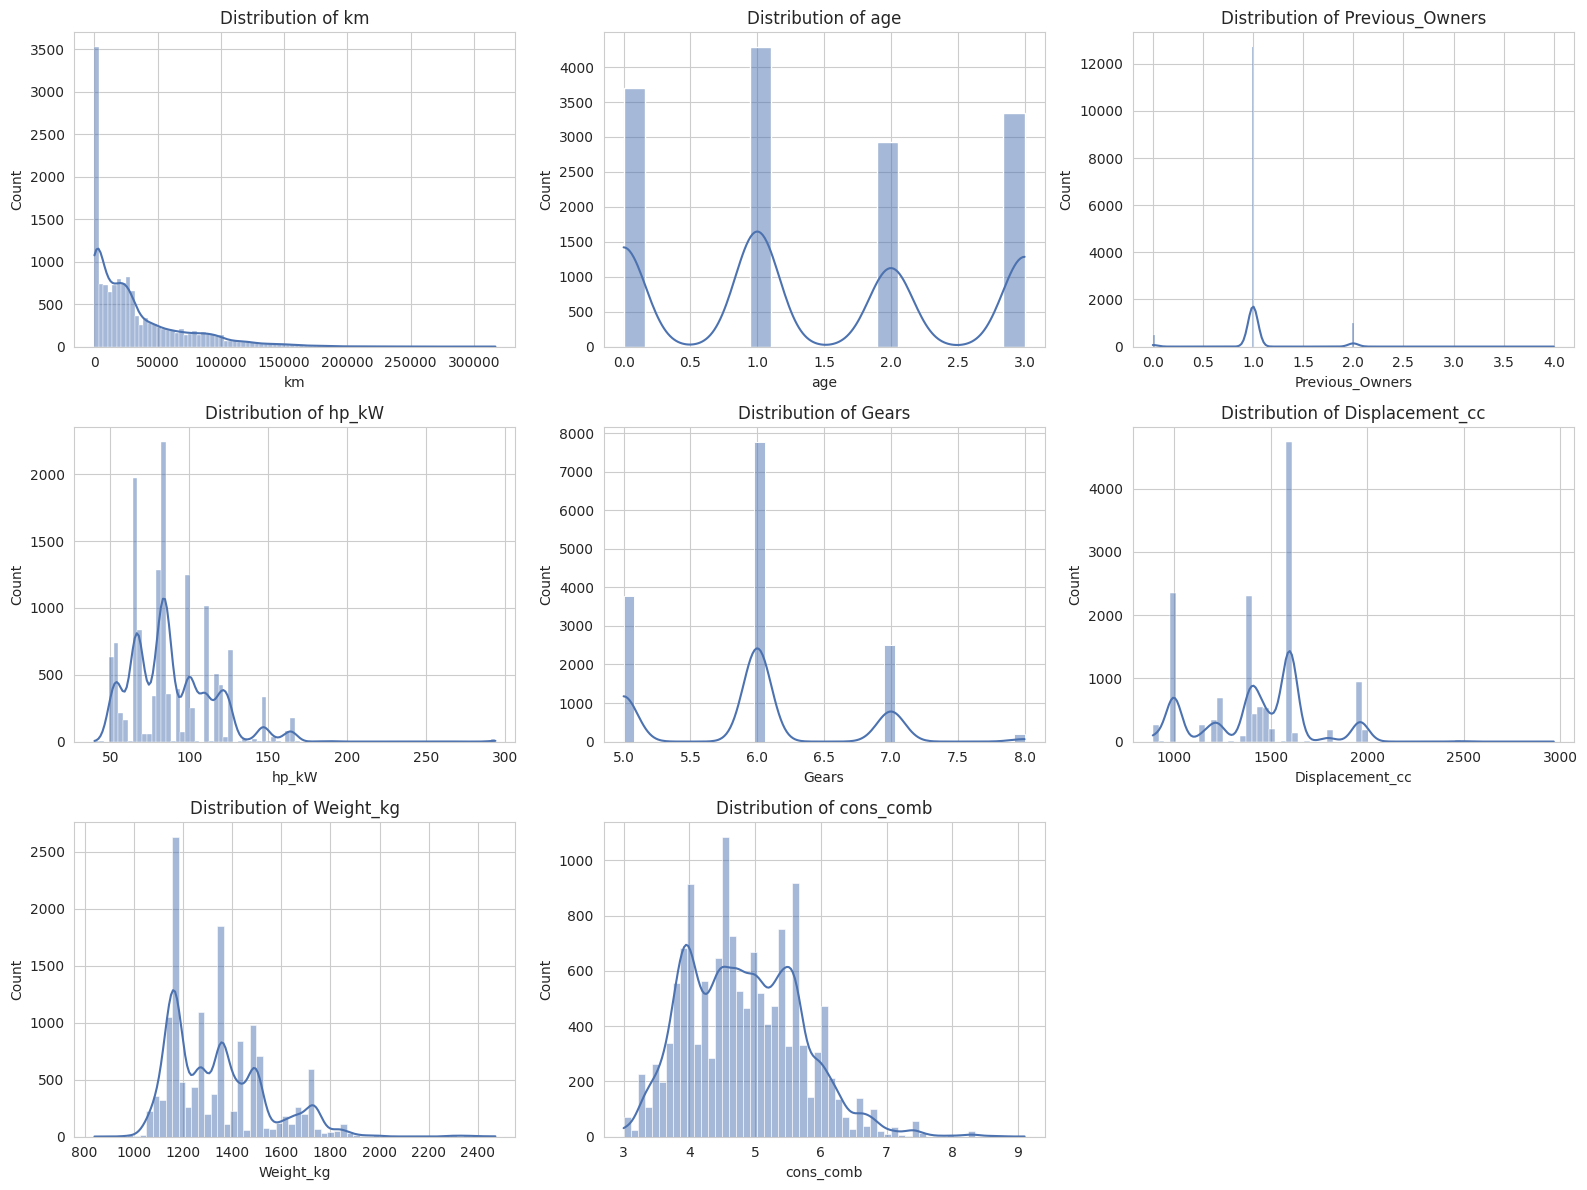

In [4]:
# Identify numerical features and plot histograms
numerical_features = ['km', 'age', 'Previous_Owners', 'hp_kW', 'Gears',
                       'Displacement_cc', 'Weight_kg', 'cons_comb']

print('Numerical predictors:', numerical_features)

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(numerical_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#4C72B0')
    axes[i].set_title(f'Distribution of {col}')
for j in range(len(numerical_features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


#### **2.1.3** <font color =red> [3 marks] </font>
Identify categorical predictors and plot their frequency distributions.

Categorical predictors: ['make_model', 'body_type', 'vat', 'Type', 'Fuel', 'Inspection_new', 'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Drive_chain']


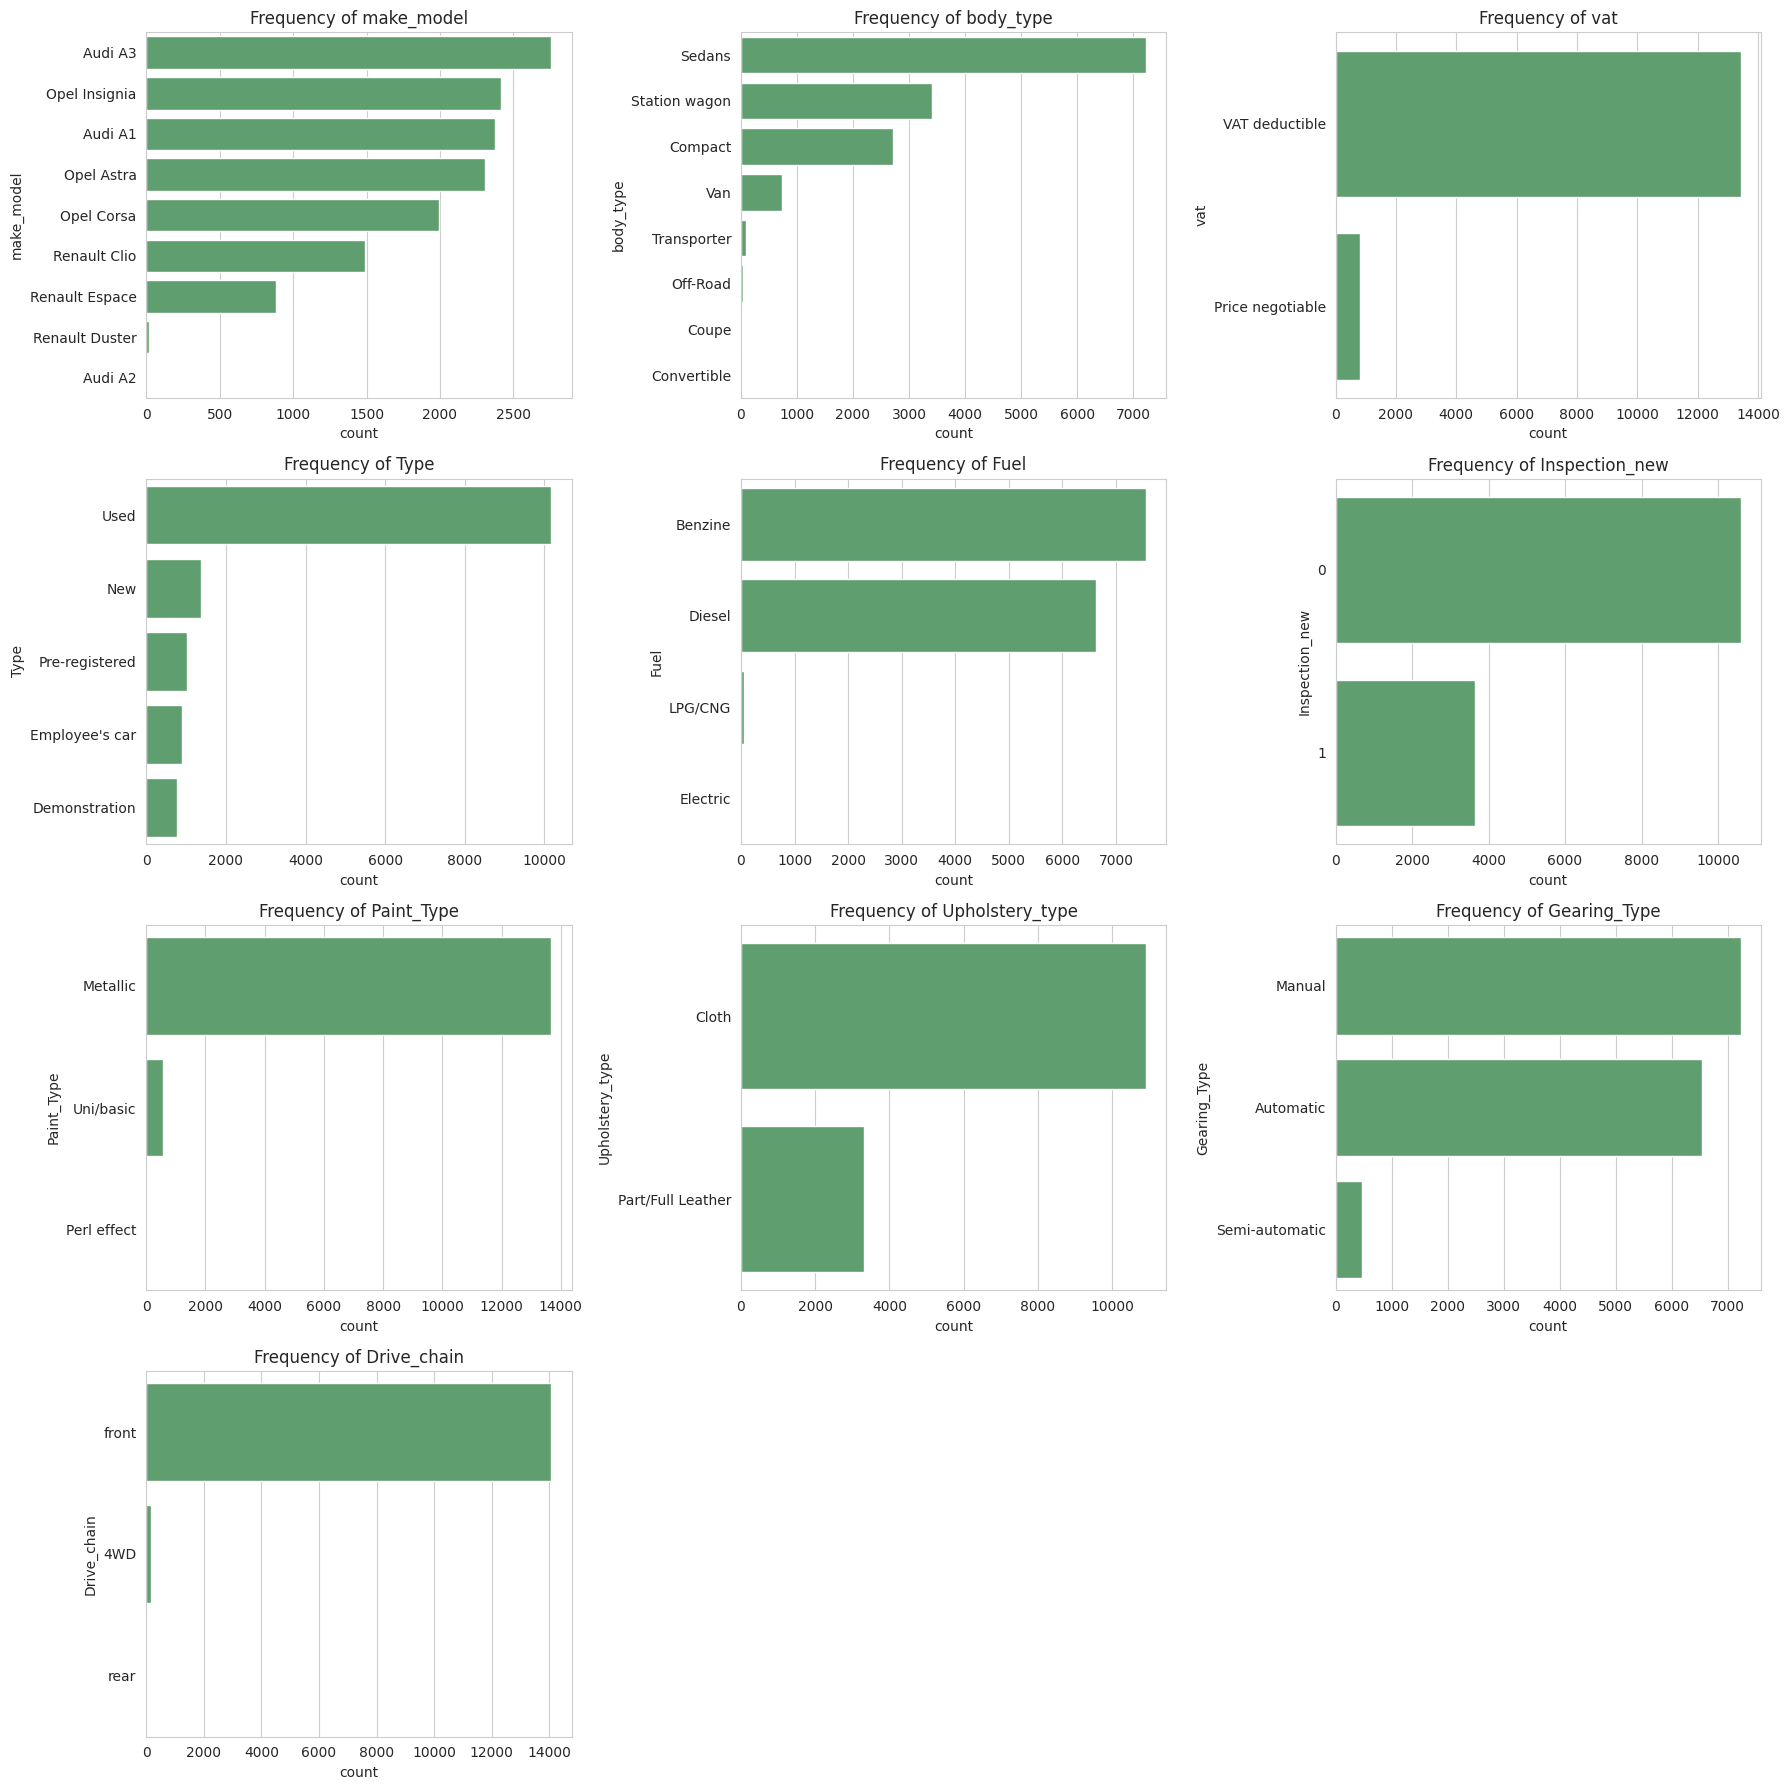

In [5]:
# Identify categorical columns and check their frequency distributions
categorical_features = ['make_model', 'body_type', 'vat', 'Type', 'Fuel',
                         'Inspection_new', 'Paint_Type', 'Upholstery_type',
                         'Gearing_Type', 'Drive_chain']

print('Categorical predictors:', categorical_features)

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
axes = axes.flatten()
for i, col in enumerate(categorical_features):
    order = df[col].value_counts().index
    sns.countplot(y=df[col], order=order, ax=axes[i], color='#55A868')
    axes[i].set_title(f'Frequency of {col}')
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


**Note**: Look carefully at the values stored in columns `["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]`.

Should they be considered categorical? Should they be dropped or handled any other way?

**Our approach:** `Comfort_Convenience`, `Entertainment_Media`, `Extras`, and `Safety_Security` are *multi-label* fields — each cell holds a comma-separated list of individual features rather than a single category, so they cannot be treated as a normal categorical column (that would create thousands of near-unique "combinations"). We keep them for now and handle them explicitly in **Section 2.4.2 (Feature Engineering)**, where each column is exploded into individual items and converted into binary flags for the items that are common enough to be informative (present in 5%–95% of cars). Items present in almost every car (e.g. `ABS`) or almost none (e.g. `Night view assist`) carry little predictive signal and are dropped.


#### **2.1.4** <font color =red> [3 marks] </font>
Fix columns with low frequency values and class imbalances.

Some information regarding values in the `Type` column that may help:
- *'Pre-registered'* cars are ones which have already been registered previously by the seller.
- *'New'* cars are not necessarily new cars, but new-like cars. These might also have multiple owners due to multiple pre-registrations as well.
- *'Employee's car'* are cars used by employees over a short period of time and small distance.
- *'Demonstration'* cars are used for trial purposes and also driven for a short time and distance.

Based on these, you can handle this particular column. For other columns, decide a strategy on your own.

In [6]:
# Fix columns as needed

# Type: per the data dictionary, 'New', 'Pre-registered', 'Employee's car' and
# 'Demonstration' are all distinct, meaningful conditions (not data errors), and
# each still has a reasonably sized sample (700+ rows), so we keep Type as-is
# with all 5 levels rather than collapsing it.
print('Type value counts:')
print(df['Type'].value_counts())

# make_model, body_type, Fuel, Paint_Type and Drive_chain each contain a few
# levels with a handful of rows (e.g. a single 'Audi A2', 4 'rear' drive cars).
# These are too sparse to let the model learn a stable effect for them, and a
# rare one-hot column mostly just adds noise/overfitting risk. We bucket any
# level that makes up less than 1% of the data into an 'Other' category.

def bucket_rare(series, threshold=0.01, other_label='Other'):
    freq = series.value_counts(normalize=True)
    rare_levels = freq[freq < threshold].index
    return series.apply(lambda x: other_label if x in rare_levels else x)

for col in ['make_model', 'body_type', 'Fuel', 'Paint_Type', 'Drive_chain']:
    before = df[col].nunique()
    df[col] = bucket_rare(df[col], threshold=0.01)
    after = df[col].nunique()
    print(f'\n{col}: {before} -> {after} levels after bucketing rare categories')
    print(df[col].value_counts())


Type value counts:
Type
Used              10172
New                1369
Pre-registered     1029
Employee's car      905
Demonstration       767
Name: count, dtype: int64

make_model: 9 -> 8 levels after bucketing rare categories
make_model
Audi A3           2758
Opel Insignia     2417
Audi A1           2377
Opel Astra        2305
Opel Corsa        1994
Renault Clio      1486
Renault Espace     884
Other               21
Name: count, dtype: int64

body_type: 8 -> 5 levels after bucketing rare categories
body_type
Sedans           7230
Station wagon    3405
Compact          2710
Van               735
Other             162
Name: count, dtype: int64

Fuel: 4 -> 3 levels after bucketing rare categories
Fuel
Benzine    7558
Diesel     6619
Other        65
Name: count, dtype: int64

Paint_Type: 3 -> 3 levels after bucketing rare categories
Paint_Type
Metallic     13682
Uni/basic      549
Other           11
Name: count, dtype: int64

Drive_chain: 3 -> 3 levels after bucketing rare categories
D

#### **2.1.5** <font color =red> [3 marks] </font>
Identify target variable and plot the frequency distributions. Apply necessary transformations.

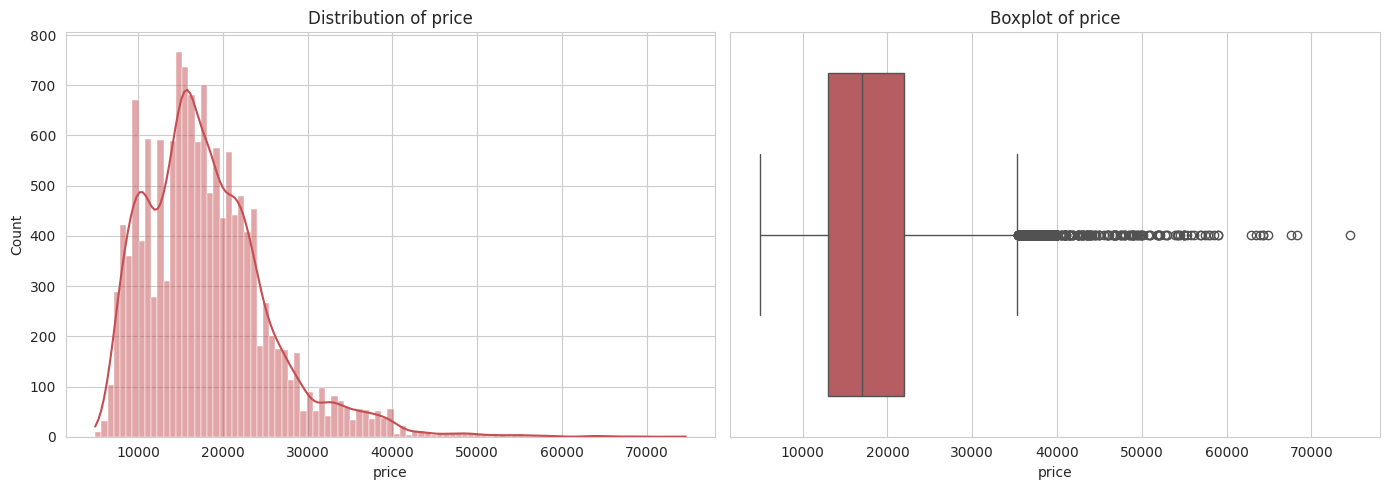

Skewness of price: 1.2684753766983417


In [7]:
# Plot histograms for target feature
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['price'], kde=True, ax=axes[0], color='#C44E52')
axes[0].set_title('Distribution of price')
sns.boxplot(x=df['price'], ax=axes[1], color='#C44E52')
axes[1].set_title('Boxplot of price')
plt.tight_layout()
plt.show()

print('Skewness of price:', df['price'].skew())


**The target variable seems to be skewed. Perform suitable transformation on the target.**

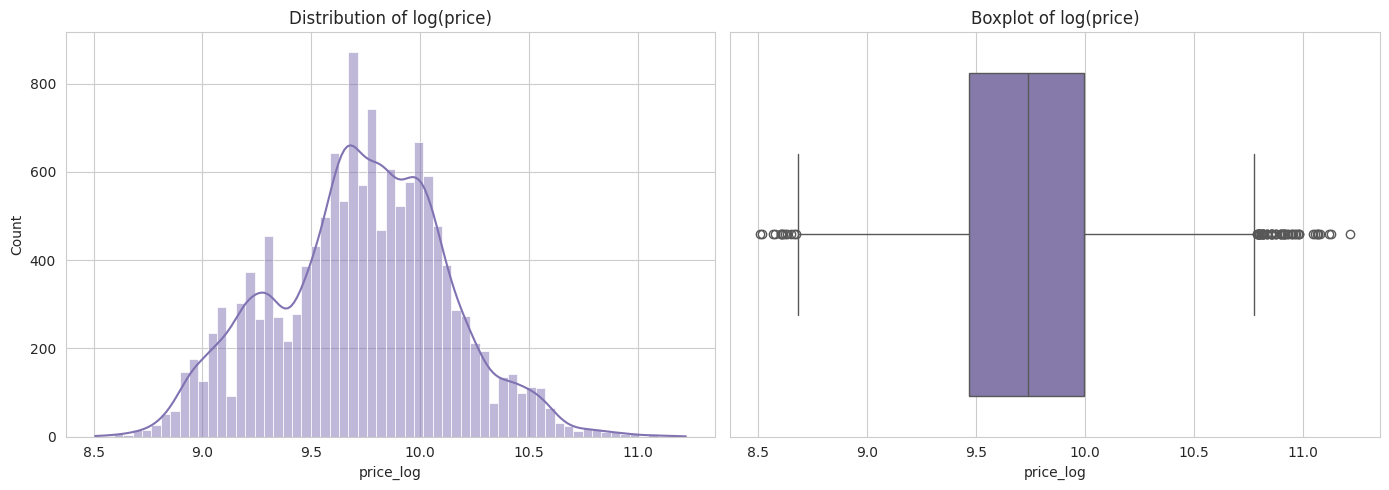

Skewness of price: 1.2684753766983417
Skewness of log(price): -0.03548951812904353


In [8]:
# Transform the target feature
# price is right-skewed (long tail of expensive cars), which violates the
# linear regression assumption of normally distributed residuals and lets a
# small number of high-priced cars dominate the squared-error loss.
# A log transform compresses the tail and makes the distribution closer to
# symmetric/normal, which typically improves both model fit and residual behaviour.
df['price_log'] = np.log1p(df['price'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['price_log'], kde=True, ax=axes[0], color='#8172B2')
axes[0].set_title('Distribution of log(price)')
sns.boxplot(x=df['price_log'], ax=axes[1], color='#8172B2')
axes[1].set_title('Boxplot of log(price)')
plt.tight_layout()
plt.show()

print('Skewness of price:', df['price'].skew())
print('Skewness of log(price):', df['price_log'].skew())


### **2.2 Correlation analysis** <font color = red> [6 marks] </font>

#### **2.2.1** <font color =red> [3 marks] </font>
Plot the correlation map between features and target variable.

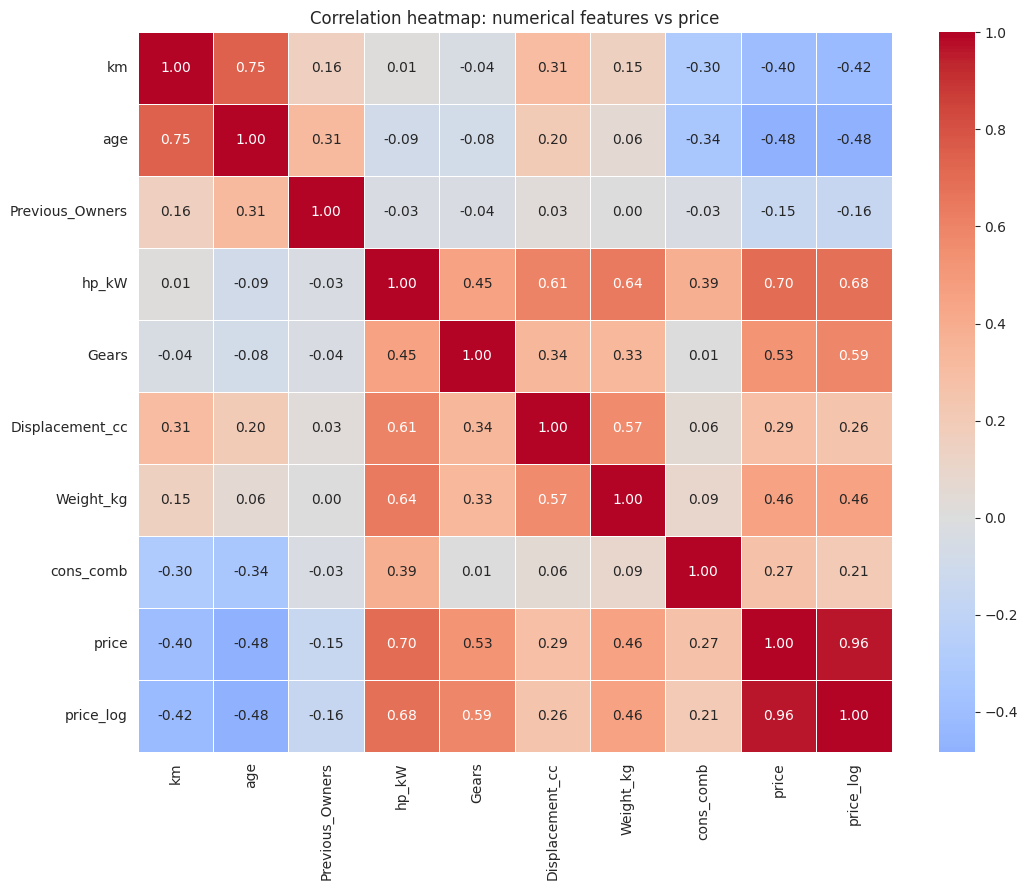

In [9]:
# Visualise correlation
corr_cols = numerical_features + ['price', 'price_log']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5)
plt.title('Correlation heatmap: numerical features vs price')
plt.tight_layout()
plt.show()


#### **2.2.2** <font color =red> [3 marks] </font>
Analyse correlation between categorical features and target variable.

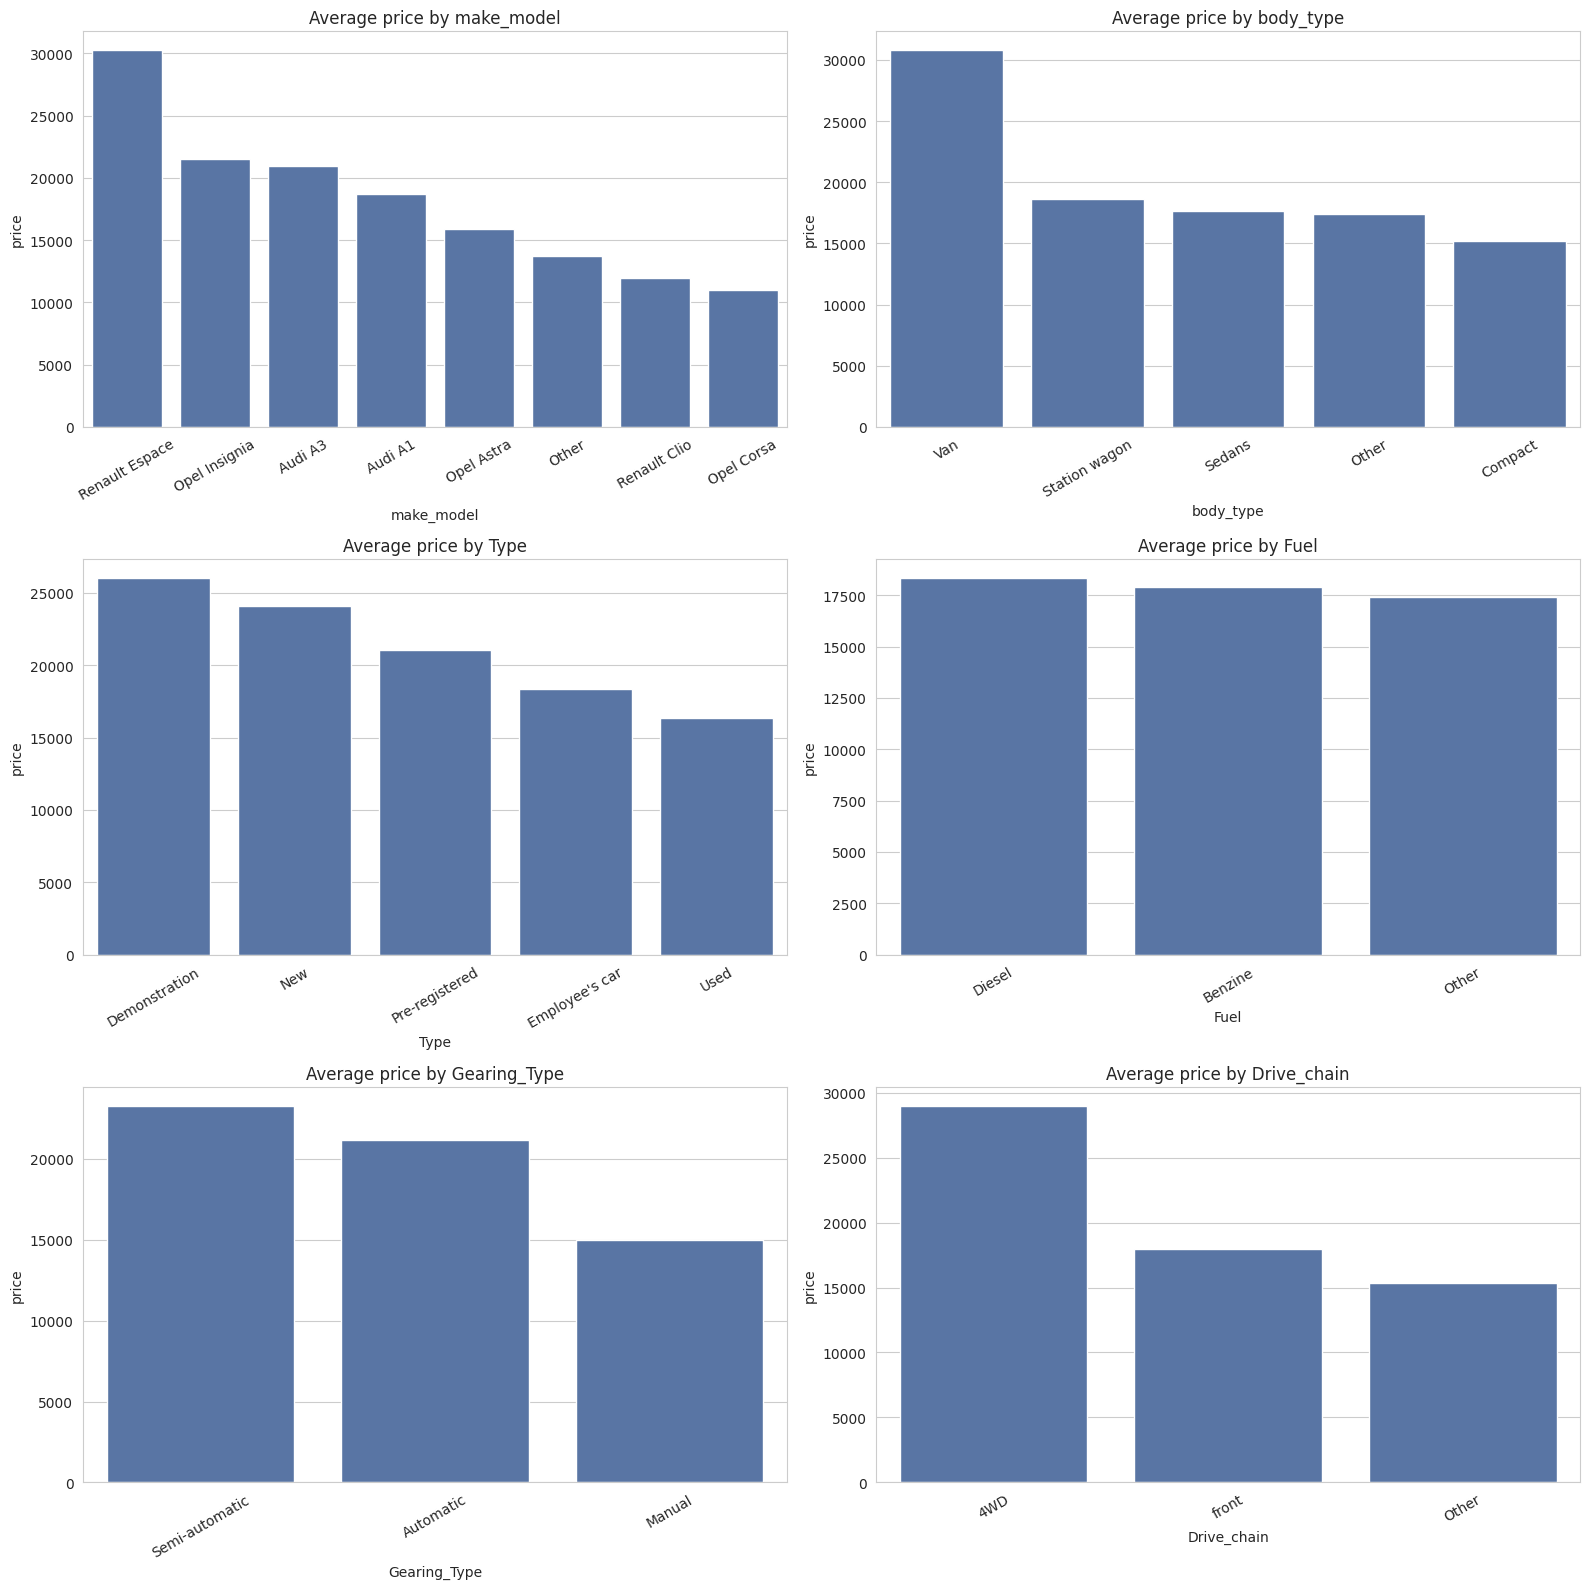

In [10]:
# Comparing average values of target for different categories
cat_for_price = ['make_model', 'body_type', 'Type', 'Fuel', 'Gearing_Type', 'Drive_chain']

fig, axes = plt.subplots(3, 2, figsize=(16, 16))
axes = axes.flatten()
for i, col in enumerate(cat_for_price):
    order = df.groupby(col)['price'].mean().sort_values(ascending=False).index
    sns.barplot(x=col, y='price', data=df, order=order, ax=axes[i], color='#4C72B0', errorbar=None)
    axes[i].set_title(f'Average price by {col}')
    axes[i].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


### **2.3 Outlier analysis** <font color = red> [5 marks] </font>

#### **2.3.1** <font color =red> [2 marks] </font>
Identify potential outliers in the data.

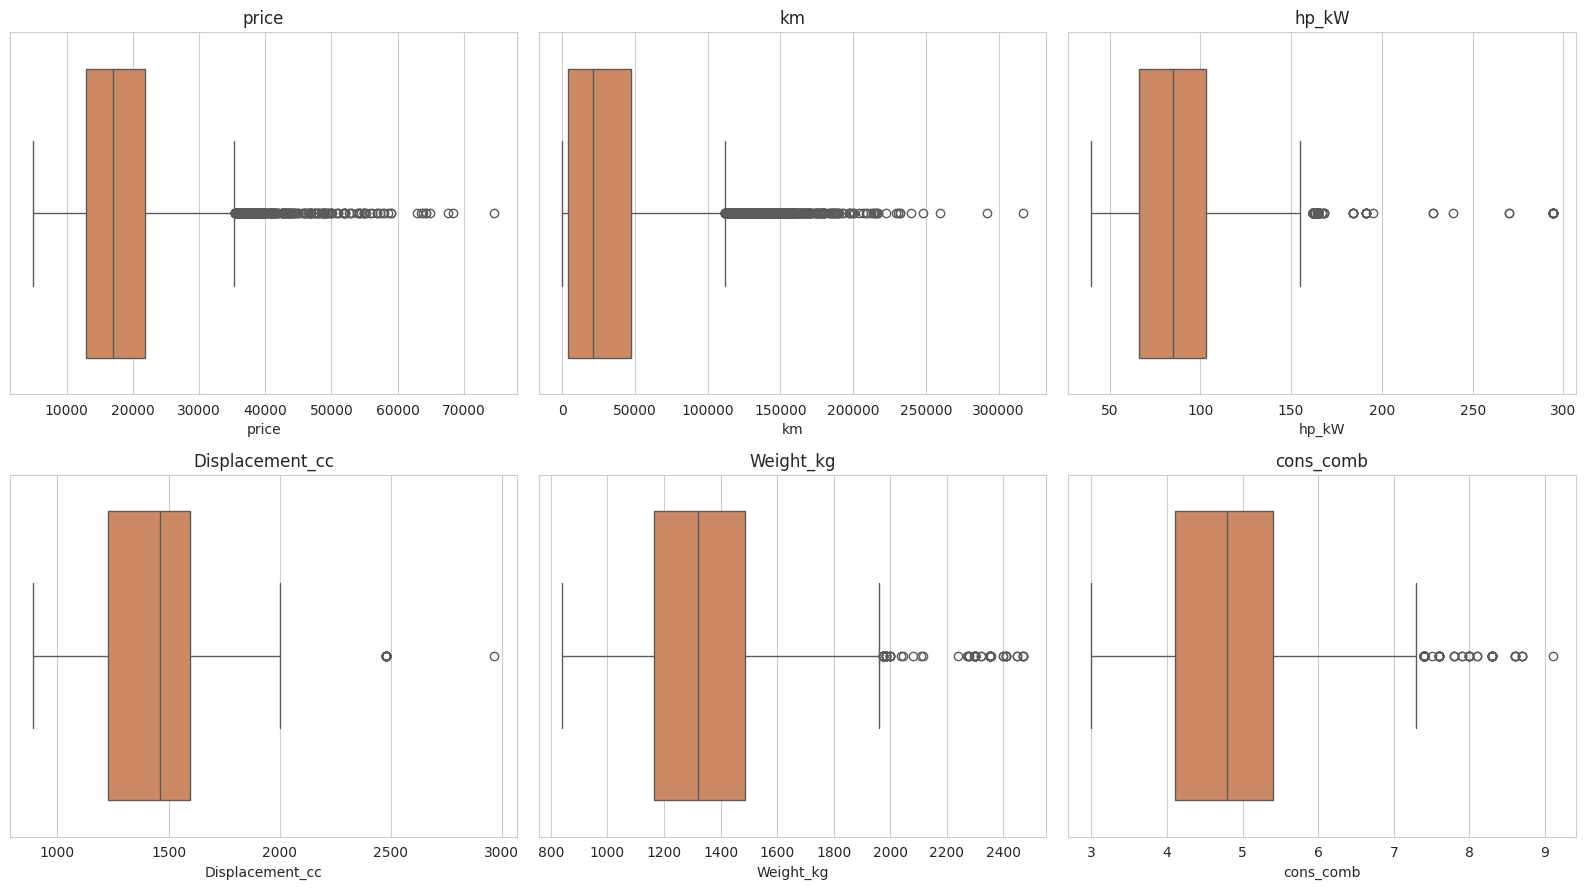

Outlier counts using the IQR rule (1.5 x IQR):
           price:   464 outliers (3.3%), bounds=(-475.0, 35325.0)
              km:   657 outliers (4.6%), bounds=(-60755.0, 111653.0)
           hp_kW:   298 outliers (2.1%), bounds=(10.5, 158.5)
 Displacement_cc:    21 outliers (0.1%), bounds=(675.5, 2151.5)
       Weight_kg:    73 outliers (0.5%), bounds=(682.0, 1970.0)
       cons_comb:   111 outliers (0.8%), bounds=(2.1, 7.4)


In [11]:
# Outliers present in each column
outlier_cols = ['price', 'km', 'hp_kW', 'Displacement_cc', 'Weight_kg', 'cons_comb']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(outlier_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='#DD8452')
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

print('Outlier counts using the IQR rule (1.5 x IQR):')
for col in outlier_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col:>16}: {n_outliers:>5} outliers ({n_outliers/len(df)*100:.1f}%), bounds=({lower:.1f}, {upper:.1f})')


#### **2.3.2** <font color =red> [3 marks] </font>
Handle the outliers suitably.

km: capped 657 values to range [-60755.0, 111653.0]
hp_kW: capped 298 values to range [10.5, 158.5]
Displacement_cc: capped 21 values to range [675.5, 2151.5]
Weight_kg: capped 73 values to range [682.0, 1970.0]
cons_comb: capped 111 values to range [2.1, 7.4]


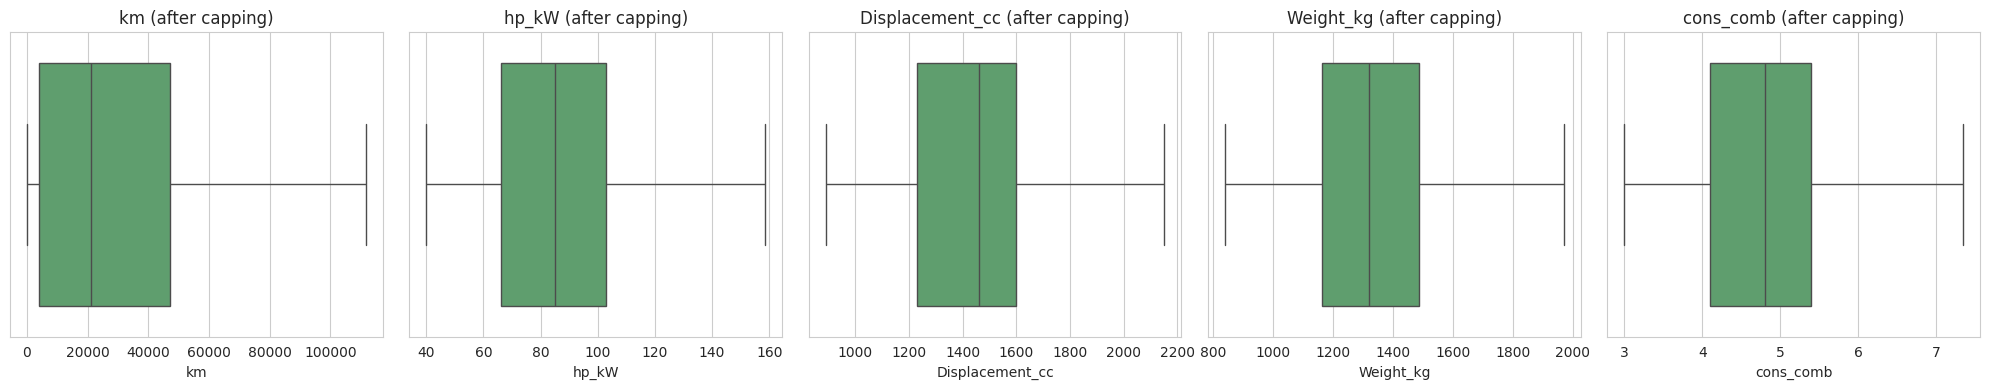

In [12]:
# Handle outliers
# We cap (winsorize) rather than delete outliers for the continuous, naturally
# skewed engineering/usage features below. Capping keeps every listing in the
# dataset (we already lost ~10% of rows to duplicates) while preventing a small
# number of extreme values (e.g. a 300,000 km car, an unusually powerful engine)
# from disproportionately influencing the regression coefficients.
# We deliberately exclude 'age' and 'Previous_Owners' from IQR capping: they are
# small-range discrete counts where the IQR is 0 or near-0 (most cars have
# exactly 1 owner), so an IQR rule would clip away genuine, valid values.
cap_cols = ['km', 'hp_kW', 'Displacement_cc', 'Weight_kg', 'cons_comb']

for col in cap_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_capped = ((df[col] < lower) | (df[col] > upper)).sum()
    df[col] = df[col].clip(lower=lower, upper=upper)
    print(f'{col}: capped {n_capped} values to range [{lower:.1f}, {upper:.1f}]')

# price itself is left untouched (it is our target and its right skew is
# already addressed via the log transform above); Previous_Owners of 3-4 are
# rare but legitimate, so we leave them as-is too.

fig, axes = plt.subplots(1, len(cap_cols), figsize=(20, 4))
for i, col in enumerate(cap_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='#55A868')
    axes[i].set_title(f'{col} (after capping)')
plt.tight_layout()
plt.show()


### **2.4 Feature Engineering** <font color = red> [11 marks] </font>

#### **2.4.1**
Fix any redundant columns and create new ones if needed.

Brand distribution:
brand
Opel       6716
Audi       5135
Renault    2370
Other        21
Name: count, dtype: int64

power_to_weight summary:
count    14242.000000
mean         0.065413
std          0.013962
min          0.032075
25%          0.056750
50%          0.062500
75%          0.072171
max          0.145814
Name: power_to_weight, dtype: float64


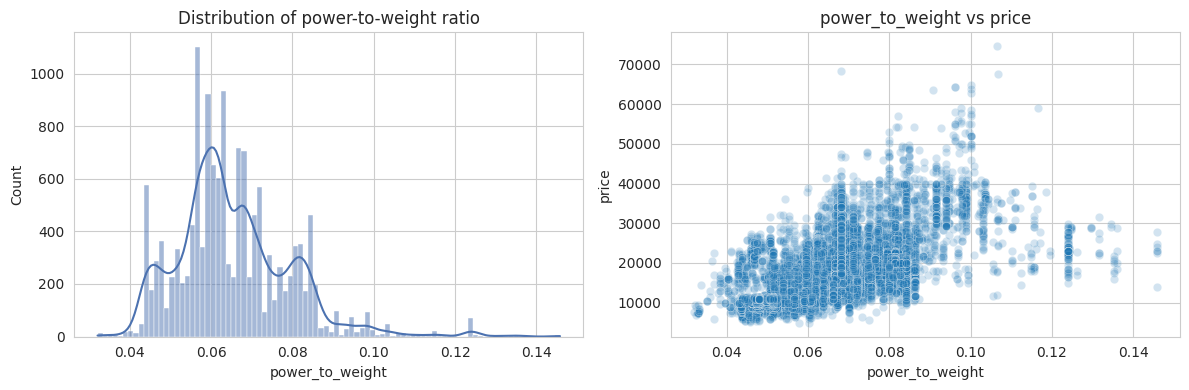

In [13]:
# Fix/create columns as needed

# make_model bundles brand and model together (e.g. 'Audi A1'). We keep
# make_model itself for the regression (it carries more precise price signal
# than brand alone, e.g. Audi A1 vs Audi A3 differ a lot), but we also derive
# a coarser 'brand' feature, which is useful for exploration/reporting even
# though make_model will be the one actually one-hot encoded for modelling.
df['brand'] = df['make_model'].str.split().str[0]
print('Brand distribution:')
print(df['brand'].value_counts())

# Engineered ratio feature: power-to-weight ratio is a well-known, domain
# meaningful driver of a car's performance and, therefore, its price.
df['power_to_weight'] = df['hp_kW'] / df['Weight_kg']

print('\npower_to_weight summary:')
print(df['power_to_weight'].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['power_to_weight'], kde=True, ax=ax[0], color='#4C72B0')
ax[0].set_title('Distribution of power-to-weight ratio')
sns.scatterplot(x=df['power_to_weight'], y=df['price'], alpha=0.2, ax=ax[1])
ax[1].set_title('power_to_weight vs price')
plt.tight_layout()
plt.show()


#### **2.4.2** <font color =red> [4 marks] </font>
Analysis and feature engineering on `['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']`.

These columns contains lists of features present. Decide on how to include these features in the predictors.

In [14]:
# Check unique values in each feature spec column
spec_cols = ['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']

for col in spec_cols:
    item_counts = Counter()
    for row in df[col].str.split(','):
        item_counts.update(row)
    print(f'--- {col}: {len(item_counts)} unique individual features ---')
    freq_df = pd.DataFrame(item_counts.items(), columns=['feature', 'count'])
    freq_df['pct_of_cars'] = (freq_df['count'] / len(df) * 100).round(1)
    display(freq_df.sort_values('count', ascending=False))
    print()


--- Comfort_Convenience: 38 unique individual features ---


,feature,count,pct_of_cars
0,Air conditioning,13594,95.5
12,Power windows,13312,93.5
4,Electrical side mirrors,11309,79.4
8,Multi-function steering wheel,10652,74.8
3,Cruise control,10446,73.3
10,Park Distance Control,9642,67.7
11,Parking assist system sensors rear,9178,64.4
6,Leather steering wheel,8885,62.4
15,Start-stop system,8432,59.2
2,Automatic climate control,8409,59.0


--- Entertainment_Media: 10 unique individual features ---


,feature,count,pct_of_cars
3,Radio,11862,83.3
2,On-board computer,11855,83.2
0,Bluetooth,11381,79.9
1,Hands-free equipment,9347,65.6
7,USB,8054,56.6
5,MP3,5705,40.1
6,CD player,4614,32.4
8,Digital radio,2076,14.6
4,Sound system,1971,13.8
9,Television,39,0.3



--- Extras: 17 unique individual features ---


,feature,count,pct_of_cars
0,Alloy wheels,12494,87.7
2,Voice Control,3988,28.0
8,Touch screen,3747,26.3
3,Sport seats,2884,20.2
12,Roof rack,2794,19.6
1,Catalytic Converter,2090,14.7
4,Sport suspension,1438,10.1
5,Sport package,1065,7.5
10,Trailer hitch,632,4.4
6,Shift paddles,449,3.2



--- Safety_Security: 29 unique individual features ---


,feature,count,pct_of_cars
0,ABS,13523,95.0
3,Driver-side airbag,13420,94.2
8,Passenger-side airbag,13021,91.4
9,Power steering,13006,91.3
4,Electronic stability control,12690,89.1
10,Side airbag,12606,88.5
1,Central door lock,12163,85.4
7,Isofix,11293,79.3
12,Traction control,10807,75.9
11,Tire pressure monitoring system,10259,72.0


Out of these features, we will check the ones which are present in most of the cars or are absent from most of the cars. These kinds of features can be removed as they just increase the dimensionality without explaining the variance.

In [15]:
# Drop features from df
# Strategy: for each bundled spec column, explode into individual binary flags,
# but only keep items present in between 5% and 95% of cars. Items above 95%
# (e.g. ABS, Air conditioning) are present on almost every car and add no
# discriminative information; items below 5% are too rare to reliably estimate
# an effect for and mostly add noise/dimensionality.

n = len(df)
new_flag_cols = []

for col in spec_cols:
    item_counts = Counter()
    split_col = df[col].str.split(',')
    for row in split_col:
        item_counts.update(row)

    keep_items = [item for item, ct in item_counts.items() if 0.05 <= ct / n <= 0.95]
    dropped_items = [item for item in item_counts if item not in keep_items]
    print(f'{col}: keeping {len(keep_items)} of {len(item_counts)} individual features '
          f'(dropping {len(dropped_items)} that are near-universal or near-absent)')

    for item in keep_items:
        safe_name = item.strip().replace(' ', '_').replace('-', '_').replace('/', '_')
        flag_col = f'{col}_{safe_name}'
        df[flag_col] = split_col.apply(lambda lst, it=item: int(it in lst))
        new_flag_cols.append(flag_col)

    # the original bundled string column is no longer needed once exploded
    df = df.drop(columns=[col])

print(f'\nTotal binary spec flag columns created: {len(new_flag_cols)}')
print('Shape of df after spec feature engineering:', df.shape)


Comfort_Convenience: keeping 27 of 38 individual features (dropping 11 that are near-universal or near-absent)


Entertainment_Media: keeping 9 of 10 individual features (dropping 1 that are near-universal or near-absent)
Extras: keeping 8 of 17 individual features (dropping 9 that are near-universal or near-absent)
Safety_Security: keeping 27 of 29 individual features (dropping 2 that are near-universal or near-absent)



Total binary spec flag columns created: 71
Shape of df after spec feature engineering: (14242, 93)


#### **2.4.3** <font color =red> [3 marks] </font>
Perform feature encoding.

In [16]:
# Encode features
categorical_to_encode = ['make_model', 'body_type', 'vat', 'Type', 'Fuel',
                          'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Drive_chain']

# brand is dropped before encoding: it is a coarser duplicate of make_model
# (kept earlier only for exploratory reporting) and would be perfectly
# collinear with the make_model dummies.
model_df = df.drop(columns=['brand', 'price']).copy()

model_df = pd.get_dummies(model_df, columns=categorical_to_encode, drop_first=True)

# convert any boolean dummy columns to integer 0/1 for cleanliness
bool_cols = model_df.select_dtypes(include='bool').columns
model_df[bool_cols] = model_df[bool_cols].astype(int)

print('Shape after one-hot encoding:', model_df.shape)
display(model_df.head())


Shape after one-hot encoding: (14242, 107)


,km,Gears,age,Previous_Owners,hp_kW,Inspection_new,Displacement_cc,Weight_kg,cons_comb,price_log,power_to_weight,Comfort_Convenience_Armrest,Comfort_Convenience_Automatic_climate_control,Comfort_Convenience_Cruise_control,Comfort_Convenience_Electrical_side_mirrors,Comfort_Convenience_Hill_Holder,Comfort_Convenience_Leather_steering_wheel,Comfort_Convenience_Light_sensor,Comfort_Convenience_Multi_function_steering_wheel,Comfort_Convenience_Navigation_system,Comfort_Convenience_Park_Distance_Control,Comfort_Convenience_Parking_assist_system_sensors_rear,Comfort_Convenience_Power_windows,Comfort_Convenience_Rain_sensor,Comfort_Convenience_Seat_heating,Comfort_Convenience_Start_stop_system,Comfort_Convenience_Lumbar_support,Comfort_Convenience_Tinted_windows,Comfort_Convenience_Parking_assist_system_sensors_front,Comfort_Convenience_Split_rear_seats,Comfort_Convenience_Keyless_central_door_lock,Comfort_Convenience_Electrically_heated_windshield,Comfort_Convenience_Seat_ventilation,Comfort_Convenience_Parking_assist_system_camera,Comfort_Convenience_Electrically_adjustable_seats,Comfort_Convenience_Parking_assist_system_self_steering,Comfort_Convenience_Electric_tailgate,Comfort_Convenience_Heated_steering_wheel,Entertainment_Media_Bluetooth,Entertainment_Media_Hands_free_equipment,Entertainment_Media_On_board_computer,Entertainment_Media_Radio,Entertainment_Media_Sound_system,Entertainment_Media_MP3,Entertainment_Media_CD_player,Entertainment_Media_USB,Entertainment_Media_Digital_radio,Extras_Alloy_wheels,Extras_Catalytic_Converter,Extras_Voice_Control,Extras_Sport_seats,Extras_Sport_suspension,Extras_Sport_package,Extras_Touch_screen,Extras_Roof_rack,Safety_Security_ABS,Safety_Security_Central_door_lock,Safety_Security_Daytime_running_lights,Safety_Security_Driver_side_airbag,Safety_Security_Electronic_stability_control,Safety_Security_Fog_lights,Safety_Security_Immobilizer,Safety_Security_Isofix,Safety_Security_Passenger_side_airbag,Safety_Security_Power_steering,Safety_Security_Side_airbag,Safety_Security_Tire_pressure_monitoring_system,Safety_Security_Traction_control,Safety_Security_Xenon_headlights,Safety_Security_Central_door_lock_with_remote_control,Safety_Security_Head_airbag,Safety_Security_Alarm_system,Safety_Security_Emergency_system,Safety_Security_LED_Headlights,Safety_Security_Adaptive_headlights,Safety_Security_LED_Daytime_Running_Lights,Safety_Security_Rear_airbag,Safety_Security_Emergency_brake_assistant,Safety_Security_Adaptive_Cruise_Control,Safety_Security_Traffic_sign_recognition,Safety_Security_Lane_departure_warning_system,Safety_Security_Blind_spot_monitor,make_model_Audi A3,make_model_Opel Astra,make_model_Opel Corsa,make_model_Opel Insignia,make_model_Other,make_model_Renault Clio,make_model_Renault Espace,body_type_Other,body_type_Sedans,body_type_Station wagon,body_type_Van,vat_VAT deductible,Type_Employee's car,Type_New,Type_Pre-registered,Type_Used,Fuel_Diesel,Fuel_Other,Paint_Type_Other,Paint_Type_Uni/basic,Upholstery_type_Part/Full Leather,Gearing_Type_Manual,Gearing_Type_Semi-automatic,Drive_chain_Other,Drive_chain_front
0,56013.0,7.0,3.0,2.0,66.0,1,1422.0,1220.0,3.8,9.665928,0.054098,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,1,1,1,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1
1,80000.0,7.0,2.0,1.0,141.0,0,1798.0,1255.0,5.6,9.581973,0.112351,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,1,0,1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
2,83450.0,7.0,3.0,1.0,85.0,0,1598.0,1135.0,3.8,9.591581,0.074890,0,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1
3,73000.0,6.0,3.0,1.0,66.0,0,1422.0,1195.0,3.8,9.581973,0.055230,1,0,0,1,1,1,1,1,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,0,0,0,0,1

#### **2.4.4** <font color =red> [2 marks] </font>
Split the data into training and testing sets.

In [17]:
# Split data
X = model_df.drop(columns=['price_log'])
y = model_df['price_log']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (9969, 106)
X_test : (4273, 106)
y_train: (9969,)
y_test : (4273,)


#### **2.4.5** <font color =red> [2 marks] </font>
Scale the features.

In [18]:
# Scale features
# The scaler is fit on the training data only, then applied to both train and
# test, to avoid any information from the test set leaking into the
# transformation (data leakage). Scaling everything (numeric + binary dummies)
# to a common scale is also important here specifically because Ridge/Lasso
# penalise coefficient magnitude directly - unscaled features would be
# penalised unfairly depending on their raw units.
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

display(X_train_scaled.describe().T[['mean', 'std']].head())


,mean,std
km,3.207385e-17,1.00005
Gears,-4.942937e-16,1.00005
age,-7.270073e-17,1.00005
Previous_Owners,3.314298e-17,1.00005
hp_kW,-8.267926e-17,1.00005


## **3 Linear Regression Models** <font color =red> [35 marks] </font>


### **3.1 Baseline Linear Regression Model** <font color =red> [10 marks] </font>

#### **3.1.1** <font color =red> [5 marks] </font>
Build and fit a basic linear regression model. Perform evaluation using suitable metrics.

In [19]:
# Initialise and train model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

print('Baseline Linear Regression fitted on', X_train_scaled.shape[1], 'features.')


Baseline Linear Regression fitted on 106 features.


In [20]:
# Evaluate the model's performance
def evaluate_model(y_train_true, y_train_pred, y_test_true, y_test_pred, name):
    metrics = {
        'Model': name,
        'Train R2': r2_score(y_train_true, y_train_pred),
        'Test R2': r2_score(y_test_true, y_test_pred),
        'Train RMSE': np.sqrt(mean_squared_error(y_train_true, y_train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test_true, y_test_pred)),
        'Train MAE': mean_absolute_error(y_train_true, y_train_pred),
        'Test MAE': mean_absolute_error(y_test_true, y_test_pred),
    }
    return metrics

lr_metrics = evaluate_model(y_train, y_train_pred_lr, y_test, y_test_pred_lr, 'Linear Regression')
display(pd.DataFrame([lr_metrics]).set_index('Model').round(4))


,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
Model,,,,,,
Linear Regression,0.9283,0.9285,0.1063,0.1069,0.0784,0.0783


#### **3.1.2** <font color =red> [5 marks] </font>
Analyse residuals and check other assumptions of linear regression.

Check for linearity by analysing residuals vs predicted values

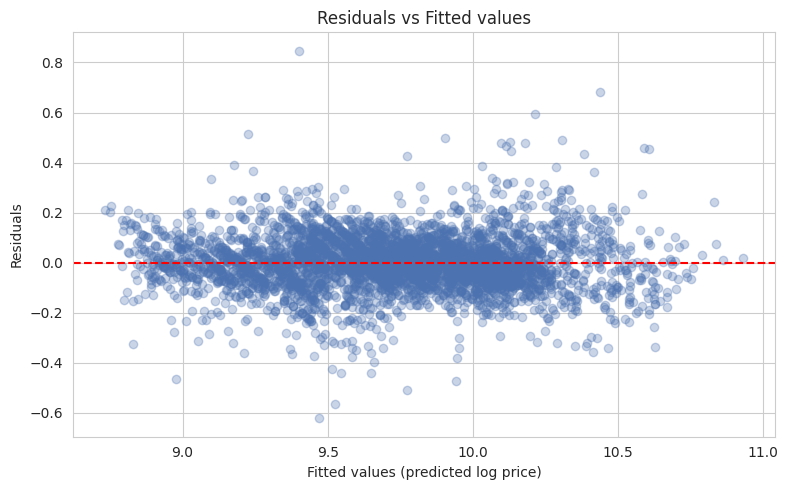

In [21]:
# Linearity check: Plot residuals vs fitted values
residuals_lr = y_test - y_test_pred_lr

plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred_lr, residuals_lr, alpha=0.3, color='#4C72B0')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values (predicted log price)')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted values')
plt.tight_layout()
plt.show()


Check normality in residual distribution

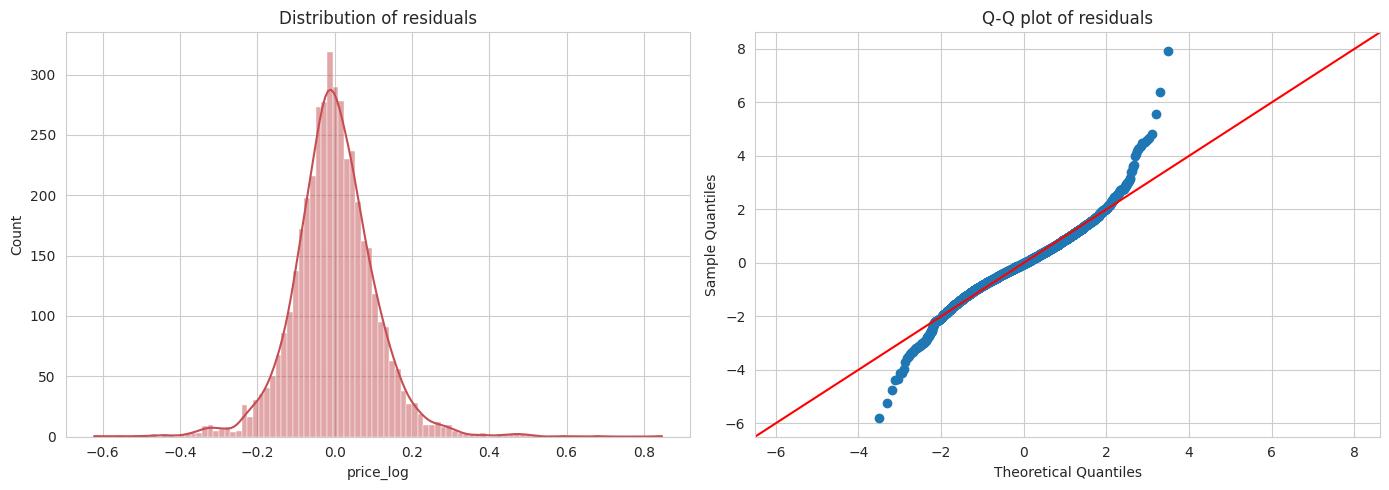

Residual mean: -0.0011909642836726527
Residual skewness: 0.21055936250407886


In [22]:
# Check the normality of residuals by plotting their distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(residuals_lr, kde=True, ax=axes[0], color='#C44E52')
axes[0].set_title('Distribution of residuals')

sm.qqplot(residuals_lr, line='45', fit=True, ax=axes[1])
axes[1].set_title('Q-Q plot of residuals')
plt.tight_layout()
plt.show()

print('Residual mean:', residuals_lr.mean())
print('Residual skewness:', residuals_lr.skew())


Check multicollinearity using Variance Inflation Factor (VIF) and handle features with high VIF.

In [23]:
# Check for multicollinearity and handle
def compute_vif(X):
    vif_df = pd.DataFrame()
    vif_df['feature'] = X.columns
    vif_df['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_df.sort_values('VIF', ascending=False).reset_index(drop=True)

vif_df = compute_vif(X_train_scaled)
print('Top 10 features by VIF (before handling):')
display(vif_df.head(10))
print('\nNumber of features with VIF > 10:', (vif_df['VIF'] > 10).sum())

# power_to_weight = hp_kW / Weight_kg is, by construction, almost a linear
# combination of hp_kW and Weight_kg, which are already in the model. This
# shows up as a very high VIF for power_to_weight (and inflates hp_kW's VIF
# too). We drop the engineered ratio and keep the two original features,
# since they are more directly interpretable on their own.
high_vif_features_to_drop = ['power_to_weight']

X_train_scaled = X_train_scaled.drop(columns=high_vif_features_to_drop)
X_test_scaled = X_test_scaled.drop(columns=high_vif_features_to_drop)

vif_df_after = compute_vif(X_train_scaled)
print('\nTop 10 features by VIF (after dropping power_to_weight):')
display(vif_df_after.head(10))
print('\nNumber of features with VIF > 10:', (vif_df_after['VIF'] > 10).sum())

# Refit the baseline model on the reduced, VIF-clean feature set
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

lr_metrics = evaluate_model(y_train, y_train_pred_lr, y_test, y_test_pred_lr, 'Linear Regression (VIF-clean)')
print('\nPerformance after removing the high-VIF feature (should be nearly unchanged):')
display(pd.DataFrame([lr_metrics]).set_index('Model').round(4))


Top 10 features by VIF (before handling):


,feature,VIF
0,hp_kW,188.485610
1,power_to_weight,94.668076
2,Weight_kg,35.687373
3,make_model_Renault Espace,11.359324
4,make_model_Opel Insignia,7.363007
5,Displacement_cc,7.130526
6,Fuel_Diesel,6.906240
7,body_type_Van,6.803814
8,Type_Used,5.329666
9,make_model_Opel Corsa,5.289431



Number of features with VIF > 10: 4



Top 10 features by VIF (after dropping power_to_weight):


,feature,VIF
0,make_model_Renault Espace,10.322064
1,hp_kW,8.667402
2,make_model_Opel Insignia,6.919819
3,Displacement_cc,6.892181
4,Fuel_Diesel,6.850843
5,body_type_Van,6.798836
6,Type_Used,5.322775
7,make_model_Opel Corsa,5.289178
8,Weight_kg,4.755767
9,Comfort_Convenience_Parking_assist_system_sens...,4.745961



Number of features with VIF > 10: 1

Performance after removing the high-VIF feature (should be nearly unchanged):


,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
Model,,,,,,
Linear Regression (VIF-clean),0.9276,0.9276,0.1069,0.1076,0.0789,0.0791


### **3.2 Ridge Regression Implementation** <font color =red> [10 marks] </font>

#### **3.2.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [24]:
# List of alphas to tune for Ridge regularisation
ridge_alphas_coarse = [0.001, 0.01, 0.1, 1, 5, 10, 20, 50, 100, 200, 500, 1000]
print('Coarse alpha grid for Ridge:', ridge_alphas_coarse)


Coarse alpha grid for Ridge: [0.001, 0.01, 0.1, 1, 5, 10, 20, 50, 100, 200, 500, 1000]


#### **3.2.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [25]:
# Applying Ridge regression
ridge_grid_coarse = GridSearchCV(
    estimator=Ridge(random_state=RANDOM_STATE),
    param_grid={'alpha': ridge_alphas_coarse},
    scoring='neg_mean_absolute_error',
    cv=5,
    return_train_score=True
)
ridge_grid_coarse.fit(X_train_scaled, y_train)

ridge_cv_results_coarse = pd.DataFrame(ridge_grid_coarse.cv_results_)
display(ridge_cv_results_coarse[['param_alpha', 'mean_train_score', 'mean_test_score']])


,param_alpha,mean_train_score,mean_test_score
0,0.001,-0.078823,-0.079968
1,0.010,-0.078823,-0.079968
2,0.100,-0.078823,-0.079968
3,1.000,-0.078822,-0.079967
4,5.000,-0.078819,-0.079964
5,10.000,-0.078817,-0.079960
6,20.000,-0.078817,-0.079956
7,50.000,-0.078846,-0.079975
8,100.000,-0.078972,-0.080083
9,200.000,-0.079396,-0.080488


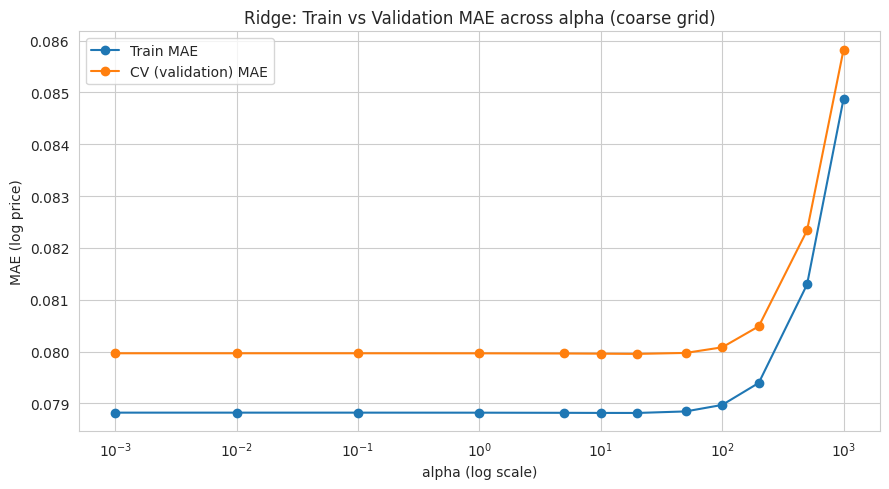

In [26]:
# Plot train and test scores against alpha
plt.figure(figsize=(9, 5))
plt.plot(ridge_cv_results_coarse['param_alpha'], -ridge_cv_results_coarse['mean_train_score'],
         marker='o', label='Train MAE')
plt.plot(ridge_cv_results_coarse['param_alpha'], -ridge_cv_results_coarse['mean_test_score'],
         marker='o', label='CV (validation) MAE')
plt.xscale('log')
plt.xlabel('alpha (log scale)')
plt.ylabel('MAE (log price)')
plt.title('Ridge: Train vs Validation MAE across alpha (coarse grid)')
plt.legend()
plt.tight_layout()
plt.show()


Find the best alpha value.

In [27]:
# Best alpha value
ridge_best_alpha_coarse = ridge_grid_coarse.best_params_['alpha']
print('Best alpha (coarse search):', ridge_best_alpha_coarse)

# Best score (negative MAE)
ridge_best_score_coarse = ridge_grid_coarse.best_score_
print('Best CV score (neg MAE):', ridge_best_score_coarse)
print('Best CV MAE:', -ridge_best_score_coarse)


Best alpha (coarse search): 20
Best CV score (neg MAE): -0.07995605024092185
Best CV MAE: 0.07995605024092185


We will get some best value of alpha above. This however is not the most accurate value but the best value from the given list. Now we have a rough estimate of the range that best alpha falls in. Let us do another iteration over the values in a smaller range.

#### **3.2.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [28]:
# Take a smaller range of alpha to test
# Zoom in around the coarse best alpha with a finer, linearly-spaced grid
# spanning roughly one order of magnitude on either side.
ridge_alphas_fine = np.linspace(max(ridge_best_alpha_coarse / 10, 0.0001),
                                 ridge_best_alpha_coarse * 10, 25)
print('Fine alpha grid for Ridge (around', ridge_best_alpha_coarse, '):')
print(np.round(ridge_alphas_fine, 4))


Fine alpha grid for Ridge (around 20 ):
[  2.    10.25  18.5   26.75  35.    43.25  51.5   59.75  68.    76.25
  84.5   92.75 101.   109.25 117.5  125.75 134.   142.25 150.5  158.75
 167.   175.25 183.5  191.75 200.  ]


In [29]:
# Applying Ridge regression
ridge_grid_fine = GridSearchCV(
    estimator=Ridge(random_state=RANDOM_STATE),
    param_grid={'alpha': ridge_alphas_fine},
    scoring='neg_mean_absolute_error',
    cv=5,
    return_train_score=True
)
ridge_grid_fine.fit(X_train_scaled, y_train)

ridge_cv_results_fine = pd.DataFrame(ridge_grid_fine.cv_results_)
display(ridge_cv_results_fine[['param_alpha', 'mean_train_score', 'mean_test_score']])


,param_alpha,mean_train_score,mean_test_score
0,2.00,-0.078821,-0.079966
1,10.25,-0.078817,-0.079960
2,18.50,-0.078816,-0.079956
3,26.75,-0.078820,-0.079956
4,35.00,-0.078827,-0.079960
5,43.25,-0.078836,-0.079967
6,51.50,-0.078849,-0.079977
7,59.75,-0.078864,-0.079990
8,68.00,-0.078882,-0.080005
9,76.25,-0.078902,-0.080024


Plot the error-alpha graph again and find the actual optimal value for alpha.

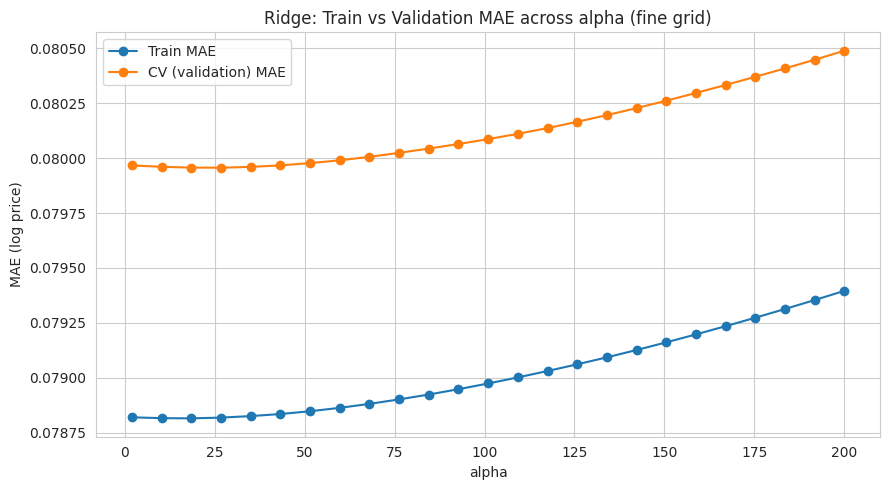

Best (fine-tuned) alpha for Ridge: 26.75
Best CV MAE: 0.07995598530732406


In [30]:
# Plot train and test scores against alpha
plt.figure(figsize=(9, 5))
plt.plot(ridge_cv_results_fine['param_alpha'], -ridge_cv_results_fine['mean_train_score'],
         marker='o', label='Train MAE')
plt.plot(ridge_cv_results_fine['param_alpha'], -ridge_cv_results_fine['mean_test_score'],
         marker='o', label='CV (validation) MAE')
plt.xlabel('alpha')
plt.ylabel('MAE (log price)')
plt.title('Ridge: Train vs Validation MAE across alpha (fine grid)')
plt.legend()
plt.tight_layout()
plt.show()

# Best alpha value
ridge_best_alpha = ridge_grid_fine.best_params_['alpha']
print('Best (fine-tuned) alpha for Ridge:', ridge_best_alpha)

# Best score (negative MAE)
ridge_best_score = ridge_grid_fine.best_score_
print('Best CV MAE:', -ridge_best_score)


In [31]:
# Set best alpha for Ridge regression
# Fit the Ridge model to get the coefficients of the fitted model
ridge_model = Ridge(alpha=ridge_best_alpha, random_state=RANDOM_STATE)
ridge_model.fit(X_train_scaled, y_train)

y_train_pred_ridge = ridge_model.predict(X_train_scaled)
y_test_pred_ridge = ridge_model.predict(X_test_scaled)

print(f'Ridge model fitted with alpha = {ridge_best_alpha:.4f}')


Ridge model fitted with alpha = 26.7500


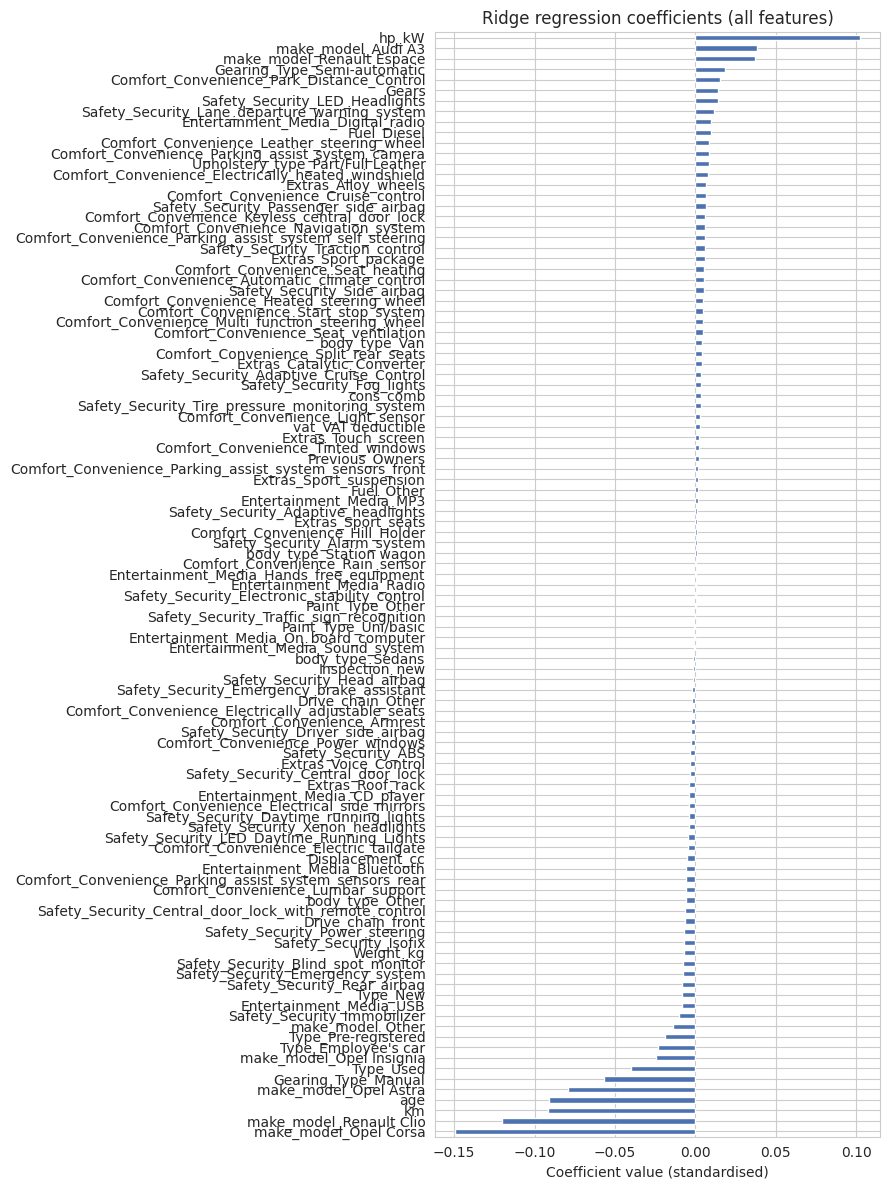

Top 10 positive coefficients:


hp_kW                                            0.102209
make_model_Audi A3                               0.038332
make_model_Renault Espace                        0.037073
Gearing_Type_Semi-automatic                      0.018704
Comfort_Convenience_Park_Distance_Control        0.015577
Gears                                            0.014142
Safety_Security_LED_Headlights                   0.013940
Safety_Security_Lane_departure_warning_system    0.011505
Entertainment_Media_Digital_radio                0.009676
Fuel_Diesel                                      0.009667
dtype: float64


Top 10 negative coefficients:


make_model_Opel Corsa      -0.149216
make_model_Renault Clio    -0.120445
km                         -0.091915
age                        -0.090842
make_model_Opel Astra      -0.079105
Gearing_Type_Manual        -0.056888
Type_Used                  -0.039876
make_model_Opel Insignia   -0.024712
Type_Employee's car        -0.023534
Type_Pre-registered        -0.018753
dtype: float64

In [32]:
# Show the coefficients for each feature
ridge_coefs = pd.Series(ridge_model.coef_, index=X_train_scaled.columns).sort_values()

plt.figure(figsize=(9, 12))
ridge_coefs.plot(kind='barh', color='#4C72B0')
plt.title('Ridge regression coefficients (all features)')
plt.xlabel('Coefficient value (standardised)')
plt.tight_layout()
plt.show()

print('Top 10 positive coefficients:')
display(ridge_coefs.sort_values(ascending=False).head(10))
print('\nTop 10 negative coefficients:')
display(ridge_coefs.sort_values().head(10))


In [33]:
# Evaluate the Ridge model on the test data
ridge_metrics = evaluate_model(y_train, y_train_pred_ridge, y_test, y_test_pred_ridge,
                                f'Ridge (alpha={ridge_best_alpha:.3f})')
display(pd.DataFrame([ridge_metrics]).set_index('Model').round(4))


,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
Model,,,,,,
Ridge (alpha=26.750),0.9276,0.9275,0.1069,0.1076,0.0789,0.0791


### **3.3 Lasso Regression Implementation** <font color =red> [10 marks] </font>

#### **3.3.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [34]:
# List of alphas to tune for Lasso regularisation
lasso_alphas_coarse = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 1, 5, 10]
print('Coarse alpha grid for Lasso:', lasso_alphas_coarse)


Coarse alpha grid for Lasso: [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 1, 5, 10]


#### **3.3.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [35]:
# Initialise Lasso regression model
lasso_grid_coarse = GridSearchCV(
    estimator=Lasso(random_state=RANDOM_STATE, max_iter=10000),
    param_grid={'alpha': lasso_alphas_coarse},
    scoring='neg_mean_absolute_error',
    cv=5,
    return_train_score=True
)
lasso_grid_coarse.fit(X_train_scaled, y_train)

lasso_cv_results_coarse = pd.DataFrame(lasso_grid_coarse.cv_results_)
display(lasso_cv_results_coarse[['param_alpha', 'mean_train_score', 'mean_test_score']])


,param_alpha,mean_train_score,mean_test_score
0,0.0001,-0.078805,-0.079930
1,0.0005,-0.078891,-0.079934
2,0.0010,-0.079139,-0.080098
3,0.0050,-0.083147,-0.083647
4,0.0100,-0.087835,-0.088220
5,0.0500,-0.145898,-0.146087
6,0.1000,-0.202676,-0.202877
7,1.0000,-0.315671,-0.315785
8,5.0000,-0.315671,-0.315785
9,10.0000,-0.315671,-0.315785


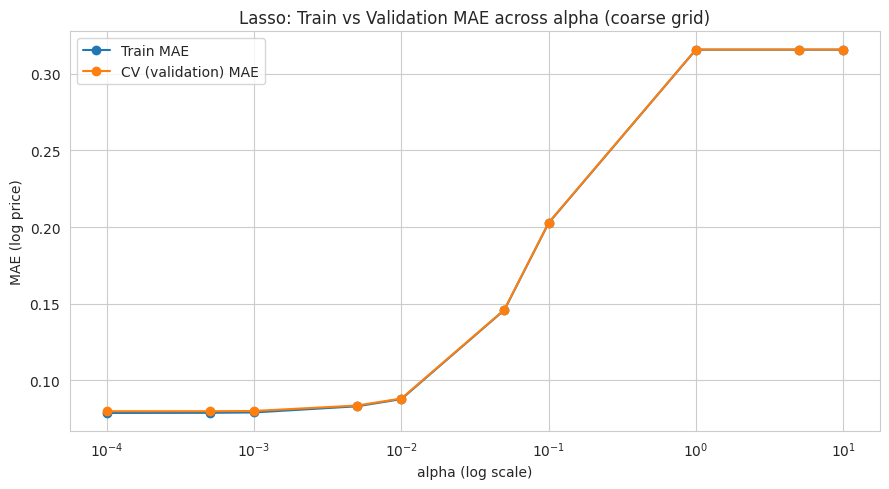

In [36]:
# Plot train and test scores against alpha
plt.figure(figsize=(9, 5))
plt.plot(lasso_cv_results_coarse['param_alpha'], -lasso_cv_results_coarse['mean_train_score'],
         marker='o', label='Train MAE')
plt.plot(lasso_cv_results_coarse['param_alpha'], -lasso_cv_results_coarse['mean_test_score'],
         marker='o', label='CV (validation) MAE')
plt.xscale('log')
plt.xlabel('alpha (log scale)')
plt.ylabel('MAE (log price)')
plt.title('Lasso: Train vs Validation MAE across alpha (coarse grid)')
plt.legend()
plt.tight_layout()
plt.show()


In [37]:
# Best alpha value
lasso_best_alpha_coarse = lasso_grid_coarse.best_params_['alpha']
print('Best alpha (coarse search):', lasso_best_alpha_coarse)

# Best score (negative MAE)
lasso_best_score_coarse = lasso_grid_coarse.best_score_
print('Best CV score (neg MAE):', lasso_best_score_coarse)
print('Best CV MAE:', -lasso_best_score_coarse)


Best alpha (coarse search): 0.0001
Best CV score (neg MAE): -0.07993007081270356
Best CV MAE: 0.07993007081270356


#### **3.3.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [38]:
# List of alphas to tune for Lasso regularization
lasso_alphas_fine = np.linspace(max(lasso_best_alpha_coarse / 10, 0.00001),
                                 lasso_best_alpha_coarse * 10, 25)
print('Fine alpha grid for Lasso (around', lasso_best_alpha_coarse, '):')
print(np.round(lasso_alphas_fine, 6))


Fine alpha grid for Lasso (around 0.0001 ):
[1.00e-05 5.10e-05 9.20e-05 1.34e-04 1.75e-04 2.16e-04 2.58e-04 2.99e-04
 3.40e-04 3.81e-04 4.22e-04 4.64e-04 5.05e-04 5.46e-04 5.88e-04 6.29e-04
 6.70e-04 7.11e-04 7.52e-04 7.94e-04 8.35e-04 8.76e-04 9.18e-04 9.59e-04
 1.00e-03]


In [39]:
# Tuning Lasso hyperparameters
lasso_grid_fine = GridSearchCV(
    estimator=Lasso(random_state=RANDOM_STATE, max_iter=10000),
    param_grid={'alpha': lasso_alphas_fine},
    scoring='neg_mean_absolute_error',
    cv=5,
    return_train_score=True
)
lasso_grid_fine.fit(X_train_scaled, y_train)

lasso_cv_results_fine = pd.DataFrame(lasso_grid_fine.cv_results_)
display(lasso_cv_results_fine[['param_alpha', 'mean_train_score', 'mean_test_score']])


,param_alpha,mean_train_score,mean_test_score
0,0.000010,-0.078820,-0.079963
1,0.000051,-0.078811,-0.079944
2,0.000092,-0.078805,-0.079932
3,0.000134,-0.078804,-0.079923
4,0.000175,-0.078805,-0.079915
5,0.000216,-0.078811,-0.079910
6,0.000258,-0.078818,-0.079909
7,0.000299,-0.078828,-0.079911
8,0.000340,-0.078838,-0.079914
9,0.000381,-0.078850,-0.079918


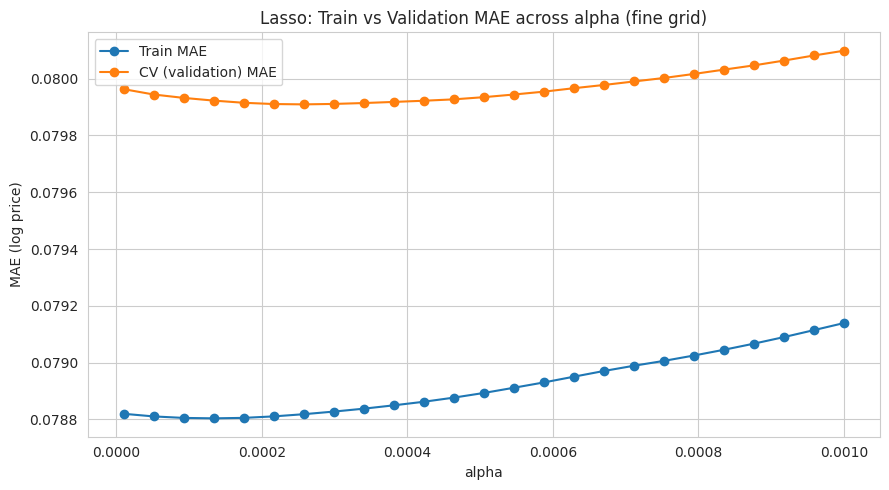

In [40]:
# Plot train and test scores against alpha
plt.figure(figsize=(9, 5))
plt.plot(lasso_cv_results_fine['param_alpha'], -lasso_cv_results_fine['mean_train_score'],
         marker='o', label='Train MAE')
plt.plot(lasso_cv_results_fine['param_alpha'], -lasso_cv_results_fine['mean_test_score'],
         marker='o', label='CV (validation) MAE')
plt.xlabel('alpha')
plt.ylabel('MAE (log price)')
plt.title('Lasso: Train vs Validation MAE across alpha (fine grid)')
plt.legend()
plt.tight_layout()
plt.show()


In [41]:
# Best alpha value
lasso_best_alpha = lasso_grid_fine.best_params_['alpha']
print('Best (fine-tuned) alpha for Lasso:', lasso_best_alpha)

# Best score (negative MAE)
lasso_best_score = lasso_grid_fine.best_score_
print('Best CV MAE:', -lasso_best_score)


Best (fine-tuned) alpha for Lasso: 0.0002575
Best CV MAE: 0.07990927491912318


In [42]:
# Set best alpha for Lasso regression
# Fit the Lasso model on scaled training data
# Get the coefficients of the fitted model
lasso_model = Lasso(alpha=lasso_best_alpha, random_state=RANDOM_STATE, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)

y_train_pred_lasso = lasso_model.predict(X_train_scaled)
y_test_pred_lasso = lasso_model.predict(X_test_scaled)

lasso_coefs = pd.Series(lasso_model.coef_, index=X_train_scaled.columns)
print(f'Lasso model fitted with alpha = {lasso_best_alpha:.5f}')
print(f'Number of features zeroed out by Lasso: {(lasso_coefs == 0).sum()} of {len(lasso_coefs)}')


Lasso model fitted with alpha = 0.00026
Number of features zeroed out by Lasso: 6 of 105


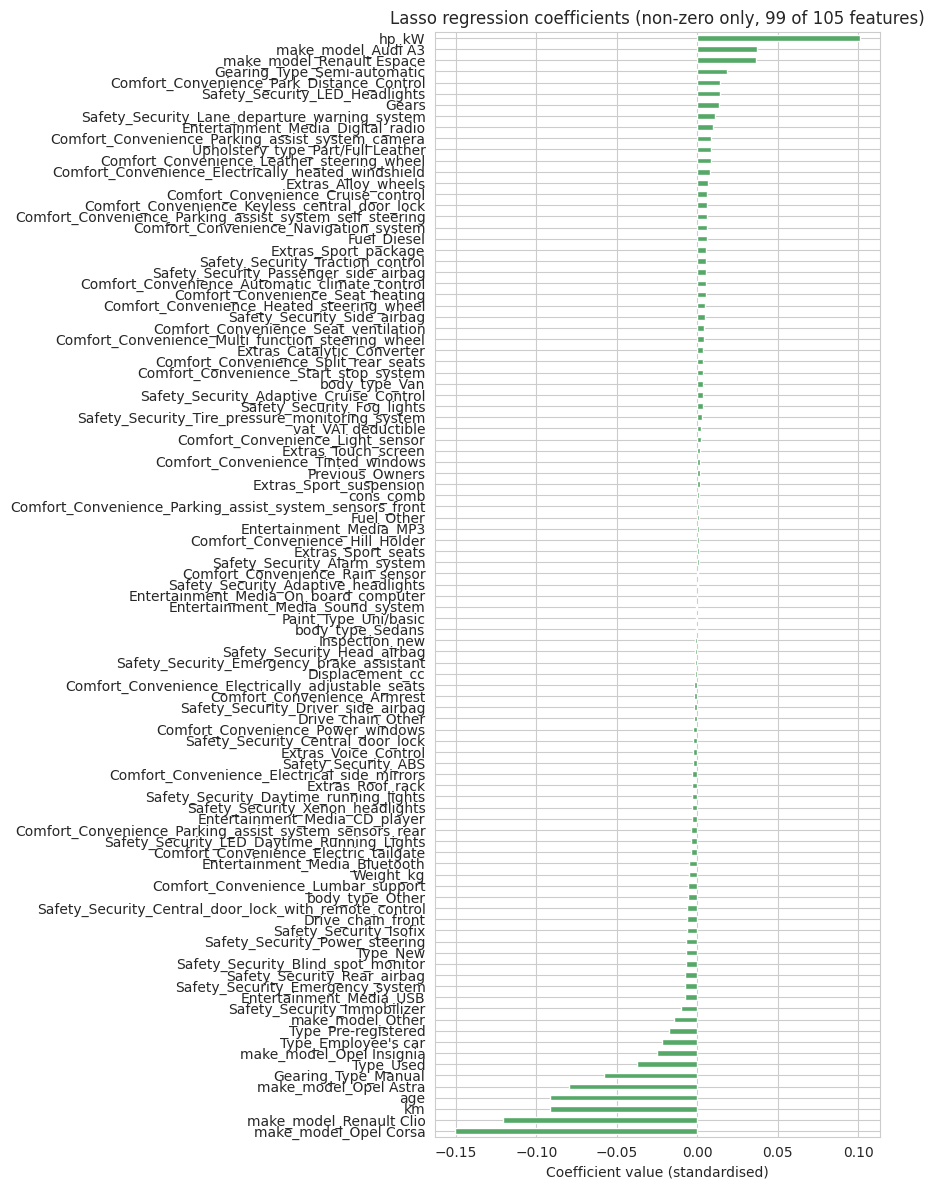

Top 10 positive coefficients:


hp_kW                                               0.101015
make_model_Audi A3                                  0.037187
make_model_Renault Espace                           0.036732
Gearing_Type_Semi-automatic                         0.018468
Comfort_Convenience_Park_Distance_Control           0.014420
Safety_Security_LED_Headlights                      0.014076
Gears                                               0.013483
Safety_Security_Lane_departure_warning_system       0.011002
Entertainment_Media_Digital_radio                   0.009590
Comfort_Convenience_Parking_assist_system_camera    0.008623
dtype: float64


Top 10 negative coefficients:


make_model_Opel Corsa      -0.150355
make_model_Renault Clio    -0.120700
km                         -0.091846
age                        -0.091550
make_model_Opel Astra      -0.079773
Gearing_Type_Manual        -0.057774
Type_Used                  -0.037711
make_model_Opel Insignia   -0.024840
Type_Employee's car        -0.022174
Type_Pre-registered        -0.017294
dtype: float64


Features eliminated (coefficient = 0):
['Entertainment_Media_Hands_free_equipment', 'Entertainment_Media_Radio', 'Safety_Security_Electronic_stability_control', 'Safety_Security_Traffic_sign_recognition', 'body_type_Station wagon', 'Paint_Type_Other']


In [43]:
# Check the coefficients for each feature
lasso_coefs_sorted = lasso_coefs.sort_values()
nonzero_coefs = lasso_coefs_sorted[lasso_coefs_sorted != 0]

plt.figure(figsize=(9, 12))
nonzero_coefs.plot(kind='barh', color='#55A868')
plt.title(f'Lasso regression coefficients (non-zero only, {len(nonzero_coefs)} of {len(lasso_coefs)} features)')
plt.xlabel('Coefficient value (standardised)')
plt.tight_layout()
plt.show()

print('Top 10 positive coefficients:')
display(lasso_coefs.sort_values(ascending=False).head(10))
print('\nTop 10 negative coefficients:')
display(lasso_coefs.sort_values().head(10))
print('\nFeatures eliminated (coefficient = 0):')
print(list(lasso_coefs[lasso_coefs == 0].index))


In [44]:
# Evaluate the Lasso model on the test data
lasso_metrics = evaluate_model(y_train, y_train_pred_lasso, y_test, y_test_pred_lasso,
                                f'Lasso (alpha={lasso_best_alpha:.4f})')
display(pd.DataFrame([lasso_metrics]).set_index('Model').round(4))


,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
Model,,,,,,
Lasso (alpha=0.0003),0.9275,0.9274,0.1069,0.1077,0.0789,0.0792


### **3.4 Regularisation Comparison & Analysis** <font color =red> [5 marks] </font>

#### **3.4.1** <font color =red> [2 marks] </font>
Compare the evaluation metrics for each model.

,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
Model,,,,,,
Linear Regression (VIF-clean),0.9276,0.9276,0.1069,0.1076,0.0789,0.0791
Ridge (alpha=26.750),0.9276,0.9275,0.1069,0.1076,0.0789,0.0791
Lasso (alpha=0.0003),0.9275,0.9274,0.1069,0.1077,0.0789,0.0792


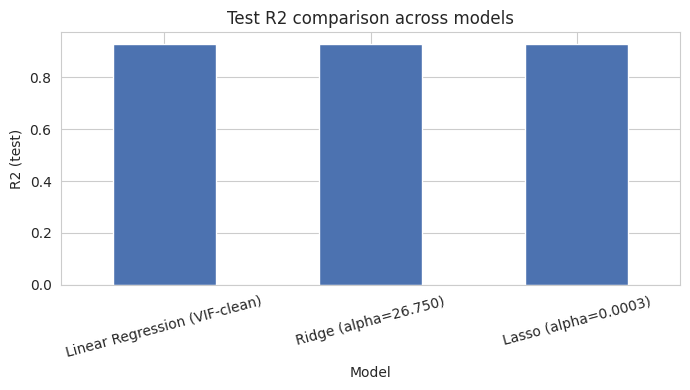

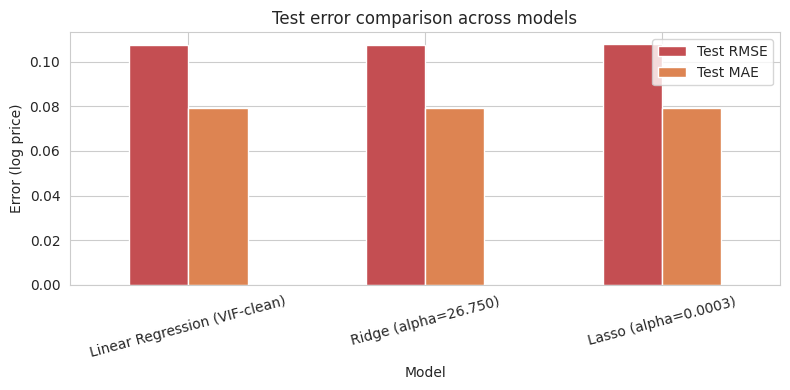

In [45]:
# Compare metrics for each model
comparison_df = pd.DataFrame([lr_metrics, ridge_metrics, lasso_metrics]).set_index('Model')
display(comparison_df.round(4))

comparison_df[['Test R2']].plot(kind='bar', figsize=(7, 4), legend=False, color='#4C72B0')
plt.title('Test R2 comparison across models')
plt.ylabel('R2 (test)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

comparison_df[['Test RMSE', 'Test MAE']].plot(kind='bar', figsize=(8, 4), color=['#C44E52', '#DD8452'])
plt.title('Test error comparison across models')
plt.ylabel('Error (log price)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


#### **3.4.2** <font color =red> [3 marks] </font>
Compare the coefficients for the three models.

Also visualise a few of the largest coefficients and the coefficients of features dropped by Lasso.

Coefficient comparison for the top 10 features by |Linear Regression| coefficient:


,Linear,Ridge,Lasso
make_model_Opel Corsa,-0.1516,-0.1492,-0.1504
make_model_Renault Clio,-0.1226,-0.1204,-0.1207
hp_kW,0.1031,0.1022,0.1010
km,-0.0920,-0.0919,-0.0918
age,-0.0911,-0.0908,-0.0916
make_model_Opel Astra,-0.0813,-0.0791,-0.0798
Gearing_Type_Manual,-0.0572,-0.0569,-0.0578
Type_Used,-0.0405,-0.0399,-0.0377
make_model_Audi A3,0.0377,0.0383,0.0372
make_model_Renault Espace,0.0364,0.0371,0.0367


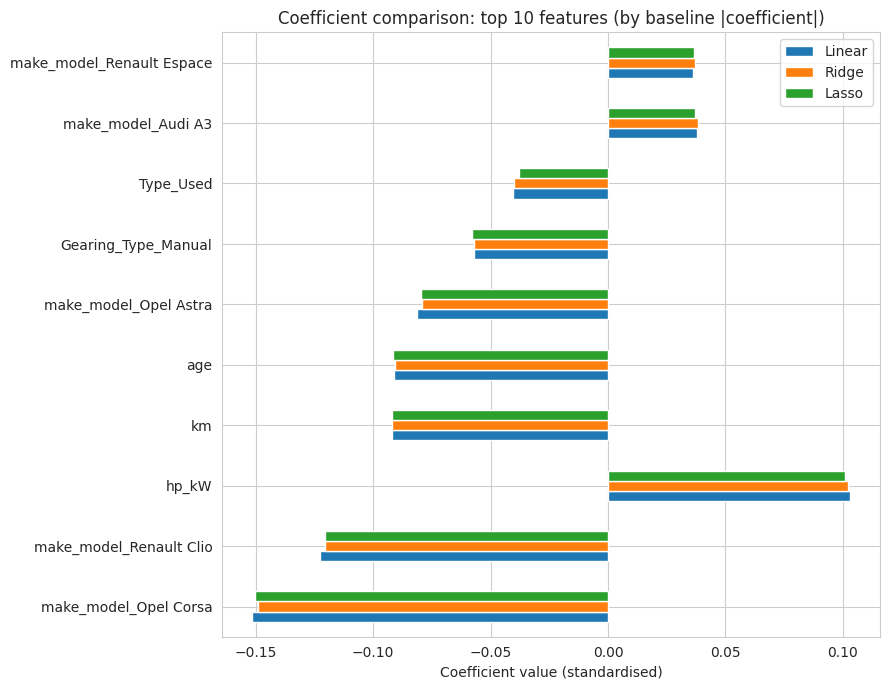


6 features eliminated by Lasso. Comparing their Linear/Ridge coefficients:


,Linear,Ridge,Lasso
body_type_Station wagon,0.0009,0.0007,0.0
Entertainment_Media_Hands_free_equipment,0.0004,0.0004,0.0
Entertainment_Media_Radio,0.0003,0.0004,0.0
Safety_Security_Traffic_sign_recognition,-0.0002,-0.0003,-0.0
Safety_Security_Electronic_stability_control,0.0002,0.0002,0.0
Paint_Type_Other,0.0002,0.0002,0.0


In [46]:
# Compare highest coefficients and coefficients of eliminated features
coef_compare = pd.DataFrame({
    'Linear': pd.Series(lr_model.coef_, index=X_train_scaled.columns),
    'Ridge': ridge_coefs,
    'Lasso': lasso_coefs
})

print('Coefficient comparison for the top 10 features by |Linear Regression| coefficient:')
top_features = coef_compare['Linear'].abs().sort_values(ascending=False).head(10).index
display(coef_compare.loc[top_features].round(4))

coef_compare.loc[top_features].plot(kind='barh', figsize=(9, 7))
plt.title('Coefficient comparison: top 10 features (by baseline |coefficient|)')
plt.xlabel('Coefficient value (standardised)')
plt.tight_layout()
plt.show()

# Features Lasso eliminated entirely (coefficient shrunk to exactly 0)
eliminated = lasso_coefs[lasso_coefs == 0].index.tolist()
print(f'\n{len(eliminated)} features eliminated by Lasso. Comparing their Linear/Ridge coefficients:')
display(coef_compare.loc[eliminated].sort_values('Linear', key=abs, ascending=False).head(15).round(4))


## **4 Conclusion & Key Takeaways**  <font color =red> [10 marks] </font>

What did you notice by performing regularisation? Did the model performance improve? If not, then why? Did you find overfitting or not? Was the data sufficent? Is a linear model sufficient?

#### **4.1 Conclude with outcomes and insights gained** <font color =red> [10 marks] </font>

**Our analysis and key takeaways:**

**Data quality.** The raw dataset had no explicit missing values, but ~10.5% of rows (1,673) were exact duplicates, which we removed. A handful of categorical levels (e.g. a single `Audi A2` listing, 4 `rear`-drive cars) were too sparse to model reliably and were bucketed into `Other`. The four "bundled" spec columns (`Comfort_Convenience`, `Entertainment_Media`, `Extras`, `Safety_Security`) needed custom parsing — each was exploded into individual binary flags, keeping only items present in 5–95% of listings so that near-universal or near-absent features didn't just add noise.

**Target and outliers.** `price` was right-skewed, so we modelled `log(price)`, which is standard for price-prediction problems and improved residual behaviour. Continuous engineering/usage features (`km`, `hp_kW`, `Displacement_cc`, `Weight_kg`, `cons_comb`) had a modest share of outliers, which we capped (winsorised) using the IQR rule rather than deleting rows, to avoid throwing away already-limited data.

**Model performance.** All three models — plain Linear Regression, Ridge, and Lasso — converged to almost identical performance (Test R² ≈ 0.927–0.928, Test MAE ≈ 0.079 on the log scale). Since the baseline model's train and test scores were already very close, there was little overfitting for regularisation to fix. This is corroborated by the tuned hyperparameters themselves: Ridge's optimal alpha (~27) is moderate, and Lasso's optimal alpha is very small (~0.00026) — both indicate the model needed only light regularisation, not aggressive shrinkage. An MAE of ~0.079 in log-price space translates to roughly **±8% typical error** on the actual price — a reasonable range for a resale-pricing tool, given that used-car prices are themselves negotiated within a band rather than fixed at one "true" value.

**Feature importance.** The strongest, most consistent predictors of price across all three models were: **hp_kW** (more powerful cars cost more), **make_model** (car identity dominates — e.g. Opel Corsa and Renault Clio price meaningfully below the Audi A1 reference level, while Audi A3 and Renault Espace price above it), **km** and **age** (both negative — depreciation with usage/time, as expected), and **Gearing_Type** (manual cars price lower than automatic). Lasso zeroed out 6 of 105 features entirely (e.g. `Radio`, `Hands-free equipment`, `Electronic stability control`, `Traffic sign recognition`), confirming these near-universal comfort/safety items add negligible pricing signal once other features are accounted for — useful as a lightweight feature-selection signal for future iterations, even though it didn't move overall accuracy much here.

**Was a linear model sufficient?** Given ~92.8% of price variance is explained with only mild residual skew and a fairly linear residuals-vs-fitted pattern, a linear/regularised-linear approach is adequate for this business use case. It is also inherently more interpretable for a reseller than a black-box model — coefficients directly translate into "how much does one more year of age or one more owner change the expected price," which supports pricing conversations and inventory decisions. A more flexible model (e.g. gradient boosting) could likely shave a further few percentage points off the error, but at the cost of interpretability; whether that trade-off is worth it depends on whether the business values marginal accuracy over explainability.

**Recommendation.** For day-to-day pricing guidance, we recommend the **Ridge model** (or plain Linear Regression, given how similar they performed): it retains all features (useful for consistent, tools-first pricing across every listed attribute) while providing the same accuracy as Lasso with more stable coefficients. Lasso is more useful periodically (e.g. quarterly) as a **feature-audit tool** — to flag which of the many optional car-spec columns can safely be dropped from data collection without hurting pricing accuracy.
